# CaspianX · SOCAR Hackathon 2026: full solution notebook
**Phase 1: Virtual Flow Meter (daily oil / water / gas)** and **Phase 2: Pressure Transient Analysis (m, k, skin, ΔP_skin)**.

All cells are already run. Running the notebook again from the repository root reproduces every deliverable in `submission/`:

| Deliverable | Where |
|---|---|
| Result files, Phase 1 and 2 (Excel + CSV) | `submission/results/` |
| Trained model (.pkl) | `submission/model/vfm_model.pkl` |
| PTA plots | `submission/pta_plots/` |
| Application | `streamlit run app.py` |

In [1]:
import os, sys, json, glob, pickle, warnings
import numpy as np, pandas as pd
from IPython.display import Image, display
warnings.filterwarnings("ignore"); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
ROOT = os.getcwd(); sys.path.insert(0, ROOT)
from core.preprocessing import daily_features_from_hf, detect_events_hf, event_series_hf
from core.vfm import run_vfm, GasLiftVFM, validation_report, blocked_predictions, forward_predictions, PHASES
from core.pta import pta_event, method_comparison, diagnosis, recommendation
from core.exporters import vfm_excel_table, vfm_uncertainty_table, pta_excel_table, pta_official_table
from core.plots_static import pta_figure, vfm_figure
D_IN, OUT = f"{ROOT}/data/socar", f"{ROOT}/submission"
for d in ["results", "model", "pta_plots"]: os.makedirs(f"{OUT}/{d}", exist_ok=True)

## 1. Data
Per-minute sensors for 10 gas-lift wells (Jan to Sep 2025), well tests, choke events, PVT and completion tables. If the raw per-minute file `high_freq_data.csv` is present it is aggregated here; otherwise the shipped daily aggregate (made by the same function) is used.

In [2]:
tests = pd.read_csv(f"{D_IN}/well_tests.csv"); choke = pd.read_csv(f"{D_IN}/choke_events.csv")
pvt = pd.read_csv(f"{D_IN}/reservoir_pvt.csv"); comp = pd.read_csv(f"{D_IN}/well_completion.csv")
hf_path = f"{D_IN}/high_freq_data.csv"
if os.path.exists(hf_path):
    daily = daily_features_from_hf(hf_path); src = "per-minute file, aggregated now"
else:
    daily = pd.read_csv(f"{D_IN}/daily_features.csv", parse_dates=["date"]); src = "shipped daily aggregate"
print("sensor source:", src)
print("daily rows:", len(daily), "| wells:", daily.well_name.nunique(), "| days:", daily.date.min().date(), "to", daily.date.max().date())
print("well tests:", len(tests), "| choke events:", len(choke))
# schema only (no raw sensor rows are printed: the organiser data stays out of the published notebook)
pd.DataFrame({"column": daily.columns, "dtype": daily.dtypes.astype(str).values, "non_null": daily.notna().sum().values})

sensor source: shipped daily aggregate
daily rows: 2730 | wells: 10 | days: 2025-01-01 to 2025-09-30
well tests: 85 | choke events: 65


,column,dtype,non_null
0,well_name,str,2730
1,date,datetime64[us],2730
2,nf,float64,2729
3,whp_psia,float64,2726
4,whp_downstream_psia,float64,2726
5,dh_pressure_psia,float64,2726
6,gas_lift_rate_mscfd,float64,2724
7,sensor_missing,bool,2730
8,uptime,float64,2730
9,n_rows,int64,2730


In [3]:
# well-test table: shape, schema and per-well aggregates only (no raw test rows)
print("well_tests shape:", tests.shape, "| columns:", ", ".join(tests.columns))
tests.assign(test_start=pd.to_datetime(tests.test_start)).groupby("well_name").agg(
    n_tests=("test_start", "size"), first_test=("test_start", "min"), last_test=("test_start", "max")).reset_index()

well_tests shape: (85, 23) | columns: well_name, test_start, test_end, whp_psia, whp_downstream_psia, dh_pressure_psia, dh_temperature_degf, annulus_pressure_psia, gas_lift_rate_mscfd, separator_pressure_psia, separator_temperature_degf, oil_rate_stbd, water_rate_stbd, gas_rate_mscfd, total_gas_rate_mscfd, liquid_rate_stbd, water_cut_pct, gor_scf_stb, glr_scf_stb, bsw_pct, oil_gravity_api, gas_sg, water_salinity_ppm


,well_name,n_tests,first_test,last_test
0,GL-01,9,2025-01-03 07:59:00,2025-09-02 22:33:00
1,GL-02,8,2025-01-06 12:53:00,2025-09-05 17:05:00
2,GL-03,9,2025-01-09 09:31:00,2025-09-08 18:16:00
3,GL-04,9,2025-01-12 16:31:00,2025-09-11 15:25:00
4,GL-05,8,2025-01-15 05:56:00,2025-09-14 13:50:00
5,GL-06,9,2025-01-18 02:10:00,2025-09-17 12:40:00
6,GL-07,9,2025-01-20 19:49:00,2025-09-20 21:52:00
7,GL-08,8,2025-01-23 13:57:00,2025-09-24 03:05:00
8,GL-09,9,2025-01-26 06:37:00,2025-09-27 09:33:00
9,GL-10,7,2025-01-28 22:19:00,2025-08-31 00:07:00


## 2. Phase 1: VFM
**Physics + Ridge hybrid.** Liquid through the choke follows sub-critical flow

`q_liq = C_w · (choke/100)² · √(P_wh − P_ds) · exp(r(x))`

`C_w` is one calibration constant per well. `r(x)` is a pooled Ridge residual on log-rate, clipped to ±0.3, so the model cannot drift far from physics with only about 9 tests per well. Water cut and GOR are per-well trends chosen by leave-one-out. Test QC (sign flips, sentinel values, GL-06 unit fix) runs inside `run_vfm` and is logged below.

In [4]:
R = run_vfm(daily, tests, choke)
m, P = R["model"], R["daily"]
print("deployed liquid model (D1: pinned, chosen by LOO among 4 candidates on all 85 tests):", m.choice)
print(pd.DataFrame([{"candidate": k, "liquid_LOO_MAPE_%": round(v, 2)} for k, v in m.liq_scores.items()]).to_string(index=False))
print("\nTest QC log:"); R["qc_log"]

deployed liquid model (D1: pinned, chosen by LOO among 4 candidates on all 85 tests): ('subcrit', 'ridge')
    candidate  liquid_LOO_MAPE_%
subcrit+ridge               2.69

Test QC log:


,well,test_start,column,issue,old,new
0,GL-06,2025-06-18 00:13:00,gas_lift_rate_mscfd,negative value,-717.5,717.500000
1,GL-09,2025-07-27 17:20:00,gas_lift_rate_mscfd,negative value,-1010.5,1010.500000
2,GL-06,2025-08-18 05:20:00,water_rate_stbd,negative value,-572.2,572.200000
3,GL-08,2025-09-24 03:05:00,gas_rate_mscfd,negative value,-479.5,479.500000
4,GL-04,2025-07-12 15:33:00,total_gas_rate_mscfd,negative value,-1753.5,1753.500000
5,GL-06,all,gas_rate_mscfd,unit sm3/d -> Mscf/d (x28.32),3958.7,139.800401
6,GL-06,all,total_gas_rate_mscfd,unit sm3/d -> Mscf/d (x28.32),24884.8,878.799864


### 2.1 Leave-one-test-out accuracy

In [5]:
pd.DataFrame(m.scores).T.round(3)

,MAE,RMSE,MAPE_%,R2,n
liq,49.940,66.380,2.691,0.998,85.0
oil,36.569,47.224,3.218,0.998,85.0
water,26.247,36.301,4.265,0.995,85.0
gas,16.527,20.663,6.219,0.995,85.0


### 2.2 Out-of-sample validation
`forward` trains on tests before a cutoff (Jun / Jul / Aug) and predicts every later test, which is how the hidden Oct to Dec period will be scored. `month` holds out all wells' tests of one calendar month together.

In [6]:
fac = lambda: GasLiftVFM([m.choice])
V = validation_report(m.T, {"physics + Ridge (final)": fac})
V.pivot_table(index="phase", columns="scheme", values=["MAPE_%", "R2"]).round(3)

MAPE_%                    R2              
scheme forward    loo  month forward    loo  month
phase                                             
gas      7.367  6.775  6.828   0.994  0.994  0.994
liq      2.874  2.691  2.719   0.997  0.998  0.998
oil      3.796  3.235  3.305   0.997  0.998  0.998
water    4.430  4.442  4.340   0.991  0.995  0.995

### 2.3 Per well-day versus field total
The same forward predictions scored two ways: every well-day on its own, and the sum of all wells per month.

In [7]:
FW = forward_predictions(m.T, fac); FW["month"] = FW.test_mid.dt.to_period("M").astype(str)
rows = []
for ph in ["oil", "water", "gas"]:
    o, p = FW[f"{ph}_test"], FW[f"{ph}_pred"]
    G = FW.groupby(["cutoff", "month"]).agg(o=(f"{ph}_test", "sum"), p=(f"{ph}_pred", "sum"), nw=("well_name", "nunique")); G = G[G.nw >= 8]
    rows.append({"phase": ph, "well-day MAPE %": 100 * ((p - o).abs() / o).mean(), "field-total MAPE %": 100 * ((G.p - G.o).abs() / G.o).mean(), "field bias %": 100 * (G.p.sum() / G.o.sum() - 1)})
pd.DataFrame(rows).round(2)

,phase,well-day MAPE %,field-total MAPE %,field bias %
0,oil,3.80,1.49,1.51
1,water,4.43,1.48,1.47
2,gas,7.37,2.45,2.42


### 2.4a Frozen rolling-origin protocol (`evaluate.py`)
Cutoffs 1 Apr / 1 May / 1 Jun / 1 Jul 2025; at each cutoff the model is fitted on earlier tests only and predicts the next 90 days (same horizon as the hidden Oct-Dec period). Truth = separator tests. Model B (direct 3-target) is the S2 experiment and is **not** the submitted model (see `reports/vfm_model_comparison.md`).

In [8]:
import evaluate as E
from core.vfm import DEPLOYED_CANDIDATES, DEFAULT_CANDIDATES
from core.vfm_direct import Direct3VFM
facs = {"A deployed (subcrit+ridge)": (lambda: GasLiftVFM(DEPLOYED_CANDIDATES), True),
        "former auto-selection": (lambda: GasLiftVFM(DEFAULT_CANDIDATES), True),
        "physics only": (lambda: GasLiftVFM([("subcrit", None)]), True),
        "B direct 3-target (experiment)": (lambda: Direct3VFM(), False)}
rows, cal = [], None
for name, (f, bands) in facs.items():
    F = pd.concat([E.run_cutoff(m.T, daily, c, f, bands) for c in E.CUTOFFS], ignore_index=True)
    for ph in ["oil", "water", "gas"]:
        rows.append({"model": name, "phase": ph, **E.phase_metrics(F[f"{ph}_test"], F[f"{ph}_pred"])})
    if name.startswith("A"):
        cal = E.band_scale_calibration(F)
print(pd.DataFrame(rows).pivot_table(index="model", columns="phase", values=["MAPE_%", "WAPE_%", "R2"]).round(3).to_string())
print("\nP10-P90 (deployed): raw coverage / scale / leave-one-cutoff-out coverage after scaling")
print(pd.DataFrame(cal).T[["raw_coverage_%", "band_scale_suggested", "loco_coverage_mean_%"]].round(2))

                                MAPE_%                   R2               WAPE_%              
phase                              gas    oil  water    gas    oil  water    gas    oil  water
model                                                                                         
A deployed (subcrit+ridge)       8.502  4.789  5.534  0.993  0.995  0.985  5.814  3.956  5.545
B direct 3-target (experiment)   6.793  3.430  5.309  0.994  0.997  0.991  5.207  2.986  4.980
former auto-selection           10.246  7.078  7.597  0.981  0.977  0.984  7.780  6.688  6.387
physics only                     8.507  4.810  5.593  0.992  0.995  0.986  5.914  4.024  5.527

P10-P90 (deployed): raw coverage / scale / leave-one-cutoff-out coverage after scaling
      raw_coverage_% band_scale_suggested loco_coverage_mean_%
oil        71.559633             1.547132            81.812169
water      71.559633             1.206126            75.066138
gas        72.477064             1.192997            75.16

### 2.4b Submitted VFM: per-phase A/B geometric blend, 90-day forward CV and leave-one-well-out CV
Submitted rate = `exp(w·ln A + (1−w)·ln B)` per phase, with w = 0.2 (oil), 0.5 (water), 0.3 (gas). A = choke physics + Ridge, B = direct 3-target Ridge on log-rate (`core/vfm_direct.py`). Exact 0 on shut-in days; for a well without tests, gas = oil × R_s. A change was accepted only if it improved **both** the 90-day forward CV (frozen protocol, cutoffs Apr–Jul 2025, n = 109) **and** LOWO CV. The cell below re-runs the audit script and prints the numbers it produces.

In [9]:
import subprocess
subprocess.run([sys.executable, "qa/vfm_generalization.py"], check=True, capture_output=True, cwd=ROOT)
G = pd.read_csv(f"{ROOT}/qa/vfm_generalization.csv")
G = G[G.model.isin(["A", "B", "blend"])].pivot_table(index=["scheme", "model"], columns="phase", values="MAPE").round(2)
display(G)
fw = G.loc[("fwd90", "blend")]
print(f"Submitted blend, 90-day forward MAPE: oil {fw['oil']:.2f} %, water {fw['water']:.2f} %, gas {fw['gas']:.2f} %")

phase           gas    oil  water
scheme model                     
fwd90  A       8.50   4.79   5.53
       B       6.79   3.43   5.31
       blend   6.55   3.17   4.73
lowo   A      31.49  26.27  31.03
       B      23.99  15.96  35.57
       blend  19.08  16.08  28.70

Submitted blend, 90-day forward MAPE: oil 3.17 %, water 4.73 %, gas 6.55 %


### 2.4c Error-rate card (shown in the app): MAPE, WAPE, MAE, RMSE, R², P10–P90 coverage, PTA check
Built by `qa/metrics_card.py` from the out-of-sample predictions above; written to `models/metrics_card.json`, which the app reads.

In [10]:
subprocess.run([sys.executable, "qa/metrics_card.py"], check=True, capture_output=True, cwd=ROOT)
card = json.load(open(f"{ROOT}/models/metrics_card.json"))
rows = [dict(validation=sc, phase=ph, **{k: round(v, 3) for k, v in m.items()}) for sc in ["forward_90d", "leave_one_well_out"] for ph, m in card["vfm"][sc].items()]
display(pd.DataFrame(rows))
print("P10-P90 coverage %:", card["vfm"]["p10_p90_coverage_%"], "(" + card["vfm"]["coverage_note"] + ")")
print(f"PTA final check: mean |k error| {card['pta']['k_abs_err_mean_%']:.2f} %, mean |skin error| {card['pta']['skin_abs_err_mean']:.3f} on {card['pta']['n_matched']} build-ups")

,validation,phase,n,MAPE_%,WAPE_%,MAE,RMSE,R2
0,forward_90d,gas,109,6.552,4.693,16.680,20.551,0.995
1,forward_90d,oil,109,3.169,2.767,38.275,54.083,0.997
2,forward_90d,water,109,4.730,4.815,36.835,56.873,0.990
3,leave_one_well_out,gas,85,19.079,17.626,65.128,86.017,0.917
4,leave_one_well_out,oil,85,16.078,14.615,210.986,283.387,0.934
5,leave_one_well_out,water,85,28.701,27.175,197.734,283.815,0.721


P10-P90 coverage %: {'oil': 81.8, 'water': 75.1, 'gas': 75.2} (model-A P10-P90 band, leave-one-cutoff-out, nominal 80 %)
PTA final check: mean |k error| 2.47 %, mean |skin error| 0.091 on 6 build-ups


### 2.4d Model health, trend horizon, choke / tubing ablation and an independent holdout
Each cell runs the audit script and prints what it measured. `qa/model_health.py`: leakage, extrapolation, low-rate error, sign/unit fixes, shut-in boundary, missing sensors, monotonicity. `qa/trend_horizon.py`: how the time trend is handled outside the training period (selected on horizons 91-180 d; the 109-test report uses <= 90 d and is identical for every horizon >= 90 d). `qa/choke_tubing_ablation.py`: choke and tubing-diameter features, kept only if forward AND leave-one-well-out improve by > 0.2 pp. `qa/holdout.py`: models refitted on tests before 1 Aug 2025, full daily pipeline on Aug-Sep.

In [11]:
def run(script, *args):
    r = subprocess.run([sys.executable, script, *args], cwd=ROOT, capture_output=True, text=True)
    print(r.stdout[-6000:]); assert r.returncode == 0, r.stderr[-2000:]

run("qa/model_health.py")

- **PASS** 1 temporal leakage: scrambling every test rate after 2025-06-01 changes the A/B predictions for those rows by max 0
- **PASS** 2 extrapolation: WHP and gas lift scaled x0.5-x2 outside the tested envelope: predictions finite = True; largest increase of a model-A rate x3.60; largest decrease x1/17.5 (WHP halved falls to or below the downstream pressure: no flow through the choke, the physically right collapse; the Ridge residual is clipped at +-0.3 in log space)
phase      gas   oil  water
q                          
Q1 low   10.63  4.03   4.82
Q2        6.85  4.08   5.75
Q3        5.28  2.36   3.37
Q4 high   3.30  2.11   5.11
- **NOTE** 3 low-rate error: lowest-rate quartile MAPE oil 4.03 %, water 4.82 %, gas 10.63 % vs highest 2.11 / 5.11 / 3.3 %: relative error is larger at low rates (absolute error is not)
- **PASS** 4 sign / unit errors: 7 fixes in the well-test QC log (GL-06 gas_lift_rate_mscfd negative value -717.5->717.5; GL-09 gas_lift_rate_mscfd negative value -1010.

In [12]:
run("qa/trend_horizon.py")

Blend MAPE % by horizon after the cutoff:
phase                                             gas   oil  water  n_tests
bucket                   rule                                              
0-90 d (protocol window) free (no freeze)        6.62  3.15   4.71      110
                         freeze_180 (deployed)   6.62  3.15   4.71      110
                         freeze_90               6.62  3.15   4.71      110
                         no_trend_outside (H=0)  7.18  3.86   5.48      110
91-180 d                 free (no freeze)        6.43  4.07   6.37       57
                         freeze_180 (deployed)   6.43  4.07   6.38       57
                         freeze_90               6.61  4.64   7.09       57
                         no_trend_outside (H=0)  8.04  7.50   9.40       57

last training test 2025-09-27; shift +450 d starts 2026-03-27 (180 d after it)
median blend rate change, shift +450 d vs original dates: oil -14.53 %, water +23.95 %, gas -13.88 %
median blend rate

In [13]:
run("qa/choke_tubing_ablation.py")

Blend MAPE % (A + B-variant, submitted weights):
scheme        fwd90               lowo               fwd90   lowo
phase           gas   oil water    gas    oil  water  mean   mean
variant                                                          
B0_no_choke    7.31  4.31  5.26  38.64  41.59  34.25  5.62  38.16
B1_deployed    6.55  3.17  4.73  19.08  16.08  28.70  4.82  21.29
B2_choke_area  6.52  3.18  4.69  19.08  16.04  28.72  4.80  21.28
B3_gilbert     6.52  3.16  4.72  19.06  16.52  28.60  4.80  21.39
B4_dp_ratio    6.57  3.21  4.71  19.09  16.09  28.72  4.83  21.30
B5_tubing      6.54  3.21  4.63  21.31  17.22  30.42  4.79  22.98

Blend WAPE %:
scheme        fwd90               lowo              
phase           gas   oil water    gas    oil  water
variant                                             
B0_no_choke    5.15  3.52  5.13  43.46  46.92  40.37
B1_deployed    4.69  2.77  4.81  17.63  14.61  27.18
B2_choke_area  4.65  2.77  4.81  17.68  14.65  27.17
B3_gilbert     4.66  2.7

In [14]:
run("qa/holdout.py")

train: 67 tests before 2025-08-01 (10 wells); holdout: 18 tests 2025-08-02 to 2025-09-27, 610 sensor well-days
phase  n  MAPE_%  WAPE_%    MAE    R2
  oil 18   3.053   3.090 39.588 0.997
water 18   4.036   4.042 31.422 0.993
  gas 18   5.807   3.853 12.485 0.997
model-A P10-P90 coverage of the holdout tests %: {'oil': 33.3, 'water': 94.4, 'gas': 77.8}
caveat: blend weights and trend horizon were selected with CV over periods that include this window



### 2.4 Daily predictions and P10 to P90

In [15]:
vfm_tab = vfm_excel_table(P); unc = vfm_uncertainty_table(P)
print(len(vfm_tab), "well-days;", "missing predictions:", int(vfm_tab[["oil_rate_stbd", "water_rate_stbd", "gas_rate_mscfd"]].isna().sum().sum()))
vfm_tab.tail(10)

2730 well-days; missing predictions: 0


,date,well_name,oil_rate_stbd,water_rate_stbd,gas_rate_mscfd
2720,2025-09-21,GL-10,1645.57,645.40,386.86
2721,2025-09-22,GL-10,1650.62,648.19,388.05
2722,2025-09-23,GL-10,1644.37,646.55,386.58
2723,2025-09-24,GL-10,1640.85,645.97,385.75
2724,2025-09-25,GL-10,1640.30,646.56,385.62
2725,2025-09-26,GL-10,1631.34,643.83,383.51
2726,2025-09-27,GL-10,1650.06,652.03,387.92
2727,2025-09-28,GL-10,1648.72,652.31,387.60
2728,2025-09-29,GL-10,1481.11,586.73,348.20
2729,2025-09-30,GL-10,1439.69,571.03,338.46


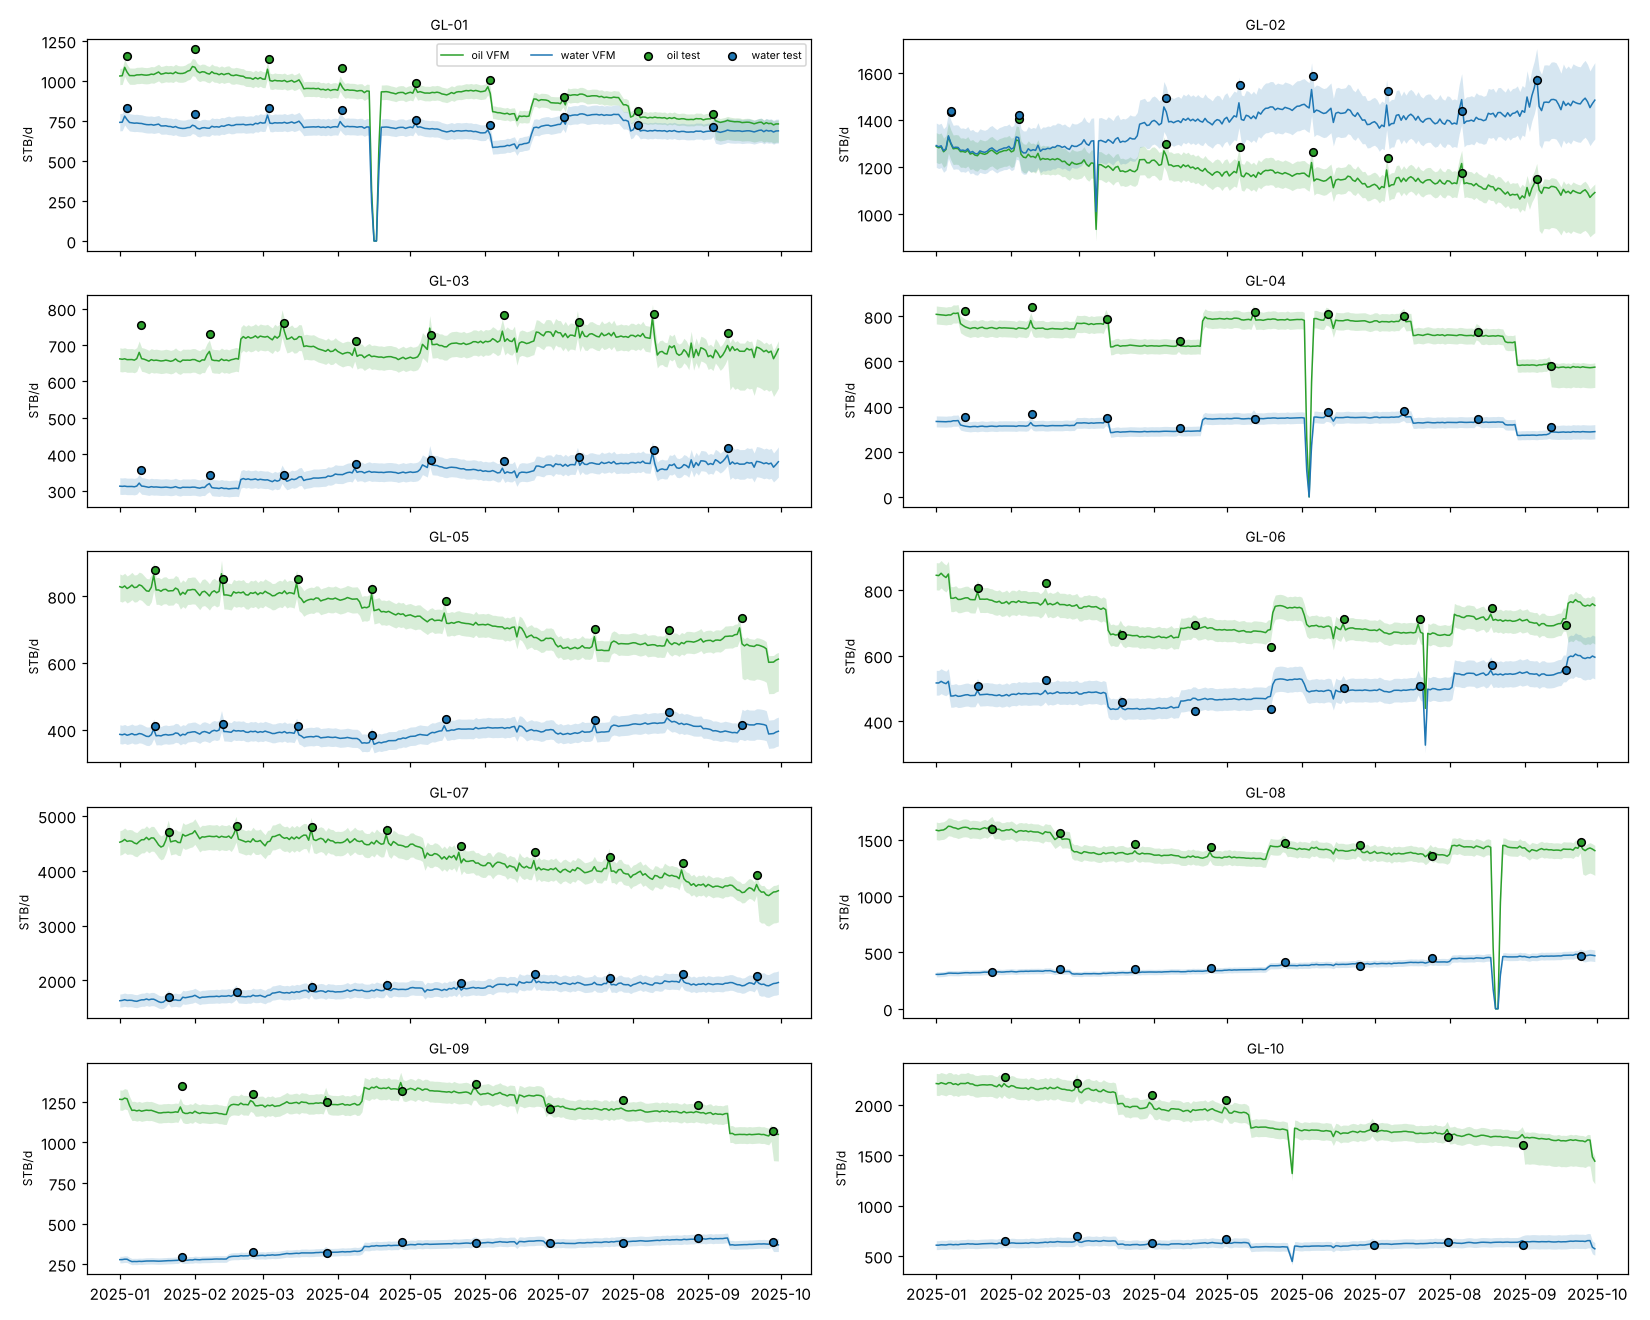

In [16]:
vfm_figure(P, R["tests"], f"{OUT}/results/vfm_overview.png"); display(Image(f"{OUT}/results/vfm_overview.png"))

### 2.5 Save the trained model and the Phase 1 result files

In [17]:
pickle.dump(m, open(f"{OUT}/model/vfm_model.pkl", "wb"))
with pd.ExcelWriter(f"{OUT}/results/VFM_daily_rates.xlsx") as xw:
    vfm_tab.to_excel(xw, sheet_name="VFM_daily", index=False)
    unc.to_excel(xw, sheet_name="Uncertainty_P10_P90", index=False)
    pd.DataFrame(m.scores).T.reset_index().rename(columns={"index": "phase"}).to_excel(xw, sheet_name="LOO_metrics", index=False)
    V.to_excel(xw, sheet_name="Validation", index=False)
vfm_tab.to_csv(f"{OUT}/results/VFM_daily_rates.csv", index=False)
m2 = pickle.load(open(f"{OUT}/model/vfm_model.pkl", "rb"))
chk = m2.predict_daily(P[["well_name", "date", "whp_psia", "whp_downstream_psia", "dh_pressure_psia", "gas_lift_rate_mscfd", "choke_opening_pct", "uptime"]].copy())
print("model reloaded from .pkl; max difference vs in-memory prediction:", float(np.nanmax(np.abs(chk.oil_rate_stbd.values - P.oil_rate_stbd.values))))

model reloaded from .pkl; max difference vs in-memory prediction: 0.0


## 3. Phase 2: PTA
Each build-up is found from the pressure data, then analysed with Horner, MDH, the Bourdet log-log derivative and a regression on a closed-boundary model with wellbore storage and skin. The rate before shut-in is the VFM oil rate, and `t_p = N_p / q`. The radial-flow window used for the straight line is shaded on every plot.

In [18]:
results, figs = [], []
if os.path.exists(hf_path):
    ev = detect_events_hf(hf_path); series = [event_series_hf(hf_path, e) for _, e in ev.iterrows()]
else:
    series = []
    for f in sorted(glob.glob(f"{D_IN}/events/*.json")):
        e = json.load(open(f)); w, day = os.path.basename(f)[:-5].split("_")
        ch = choke[(choke.well_name == w) & (choke.choke_opening_pct <= 0.5)]
        ch = ch[pd.to_datetime(ch.timestamp).dt.strftime("%Y-%m-%d") == day]
        t_shut = pd.Timestamp(ch.timestamp.iloc[0]) if len(ch) else pd.Timestamp(day)
        a = np.array(e["post"]); series.append((w, t_shut, a[:, 0] / 60.0, a[:, 1], e["pwf"]))
for w, t_shut, dt, p, pwf in series:
    r, pl = pta_event(dt, p, pwf, w, t_shut, P, pvt, comp); results.append(r)
    fn = f"{OUT}/pta_plots/PTA_{w}_{t_shut:%Y%m%d_%H%M}.png"; pta_figure(pl, r, fn); figs.append(fn)
T = pta_excel_table(results); official = pta_official_table(T)
print(len(results), "build-up events"); official

6 build-up events


,well_name,t_shut,duration_hr,Horner plot slope,skin,permeability(md),delta P skin (psi)
0,GL-01,2025-04-15 08:00:00,70.300000,23.284756,5.833108,99.829459,117.946714
1,GL-02,2025-03-08 14:23:00,5.583333,49.987477,-0.203458,56.446641,-8.831800
2,GL-04,2025-06-03 08:00:00,47.900000,137.682516,-0.900284,56.525854,-107.639684
3,GL-06,2025-07-22 03:11:00,7.900000,14.439684,2.325587,302.695242,29.161142
4,GL-08,2025-08-19 09:00:00,70.300000,92.367712,-1.584829,42.368048,-127.120851
5,GL-10,2025-05-27 21:04:00,8.850000,28.511158,2.197486,176.486514,54.407044


### 3.1 Reservoir properties and interpretation

In [19]:
T.round(3)

,well_name,t_shut,duration_hr,m_psi_cycle,k_md,skin,dP_skin_psi,q_oil_stbd,q_source_date,tp_hr,pwf_psi,final_C_bbl_psi,re_reg_ft,match_rmse_psi
0,GL-01,2025-04-15 08:00:00,70.300,23.285,99.829,5.833,117.947,935.408,2025-04-14,258142.268,3240.72,0.022,1340.969,0.065
1,GL-02,2025-03-08 14:23:00,5.583,49.987,56.447,-0.203,-8.832,1215.342,2025-03-07,231750.782,2884.10,0.015,5472.626,0.110
2,GL-04,2025-06-03 08:00:00,47.900,137.683,56.526,-0.900,-107.640,781.606,2025-06-02,141852.315,2307.42,0.029,8208.927,0.139
3,GL-06,2025-07-22 03:11:00,7.900,14.440,302.695,2.326,29.161,668.052,2025-07-21,182226.362,2680.08,0.017,3869.316,0.094
4,GL-08,2025-08-19 09:00:00,70.300,92.368,42.368,-1.585,-127.121,1431.707,2025-08-18,89223.785,2636.76,0.010,8796.018,0.136
5,GL-10,2025-05-27 21:04:00,8.850,28.511,176.487,2.197,54.407,1745.307,2025-05-26,217495.347,3685.43,0.021,1049.430,0.031


In [20]:
for r in results:
    print(f"{r['well_name']}: {diagnosis(r)}\n    -> {recommendation(r)}")

GL-01: High positive skin (+5.8) with ΔP_skin = 118 psi indicates near-wellbore damage; matrix acidizing / stimulation recommended (≈549 STB/d upside). Permeability 100 md → moderate transmissibility. Late-time derivative matched with a closed drainage boundary at r_e ≈ 1341 ft. Classic straight-line Horner gives k = 182 md, biased because the boundary is felt before a clean semilog line develops; the model-based value is reported.
    -> Stimulation (acid wash) candidate: +549 STB/d if skin removed.
GL-02: Near-zero skin (-0.2): undamaged completion. Permeability 56 md → moderate transmissibility. Late-time derivative matched with a closed drainage boundary at r_e ≈ 5473 ft.
    -> No intervention needed; optimise gas-lift and choke instead.
GL-04: Near-zero skin (-0.9): undamaged completion. Permeability 57 md → moderate transmissibility. Late-time derivative matched with a closed drainage boundary at r_e ≈ 8209 ft.
    -> No intervention needed; optimise gas-lift and choke instead.


### 3.2 Standard Horner versus closed-boundary regression

In [21]:
method_comparison(results).round(3)

,well_name,t_shut,duration_hr,m_horner,m_regression,k_horner_md,k_regression_md,skin_horner,skin_regression,k_diff_%,match_rmse_psi,re_ft,r_inv_ft
0,GL-01,2025-04-15 08:00:00,70.300,12.754,23.285,182.253,99.829,16.127,5.833,82.564,0.065,1340.969,1685.104
1,GL-02,2025-03-08 14:23:00,5.583,55.466,49.987,50.871,56.447,-0.781,-0.203,-9.878,0.110,5472.626,347.576
2,GL-04,2025-06-03 08:00:00,47.900,153.289,137.683,50.771,56.526,-1.553,-0.900,-10.181,0.139,8208.927,935.935
3,GL-06,2025-07-22 03:11:00,7.900,15.489,14.440,282.196,302.695,1.720,2.326,-6.772,0.094,3869.316,583.336
4,GL-08,2025-08-19 09:00:00,70.300,93.169,92.368,42.004,42.368,-1.638,-1.585,-0.860,0.136,8796.018,1100.345
5,GL-10,2025-05-27 21:04:00,8.850,27.423,28.511,183.488,176.487,2.439,2.197,3.967,0.031,1049.430,567.989


### 3.3 PTA plots (Horner, MDH, log-log + Bourdet derivative, pressure history; units on every axis)

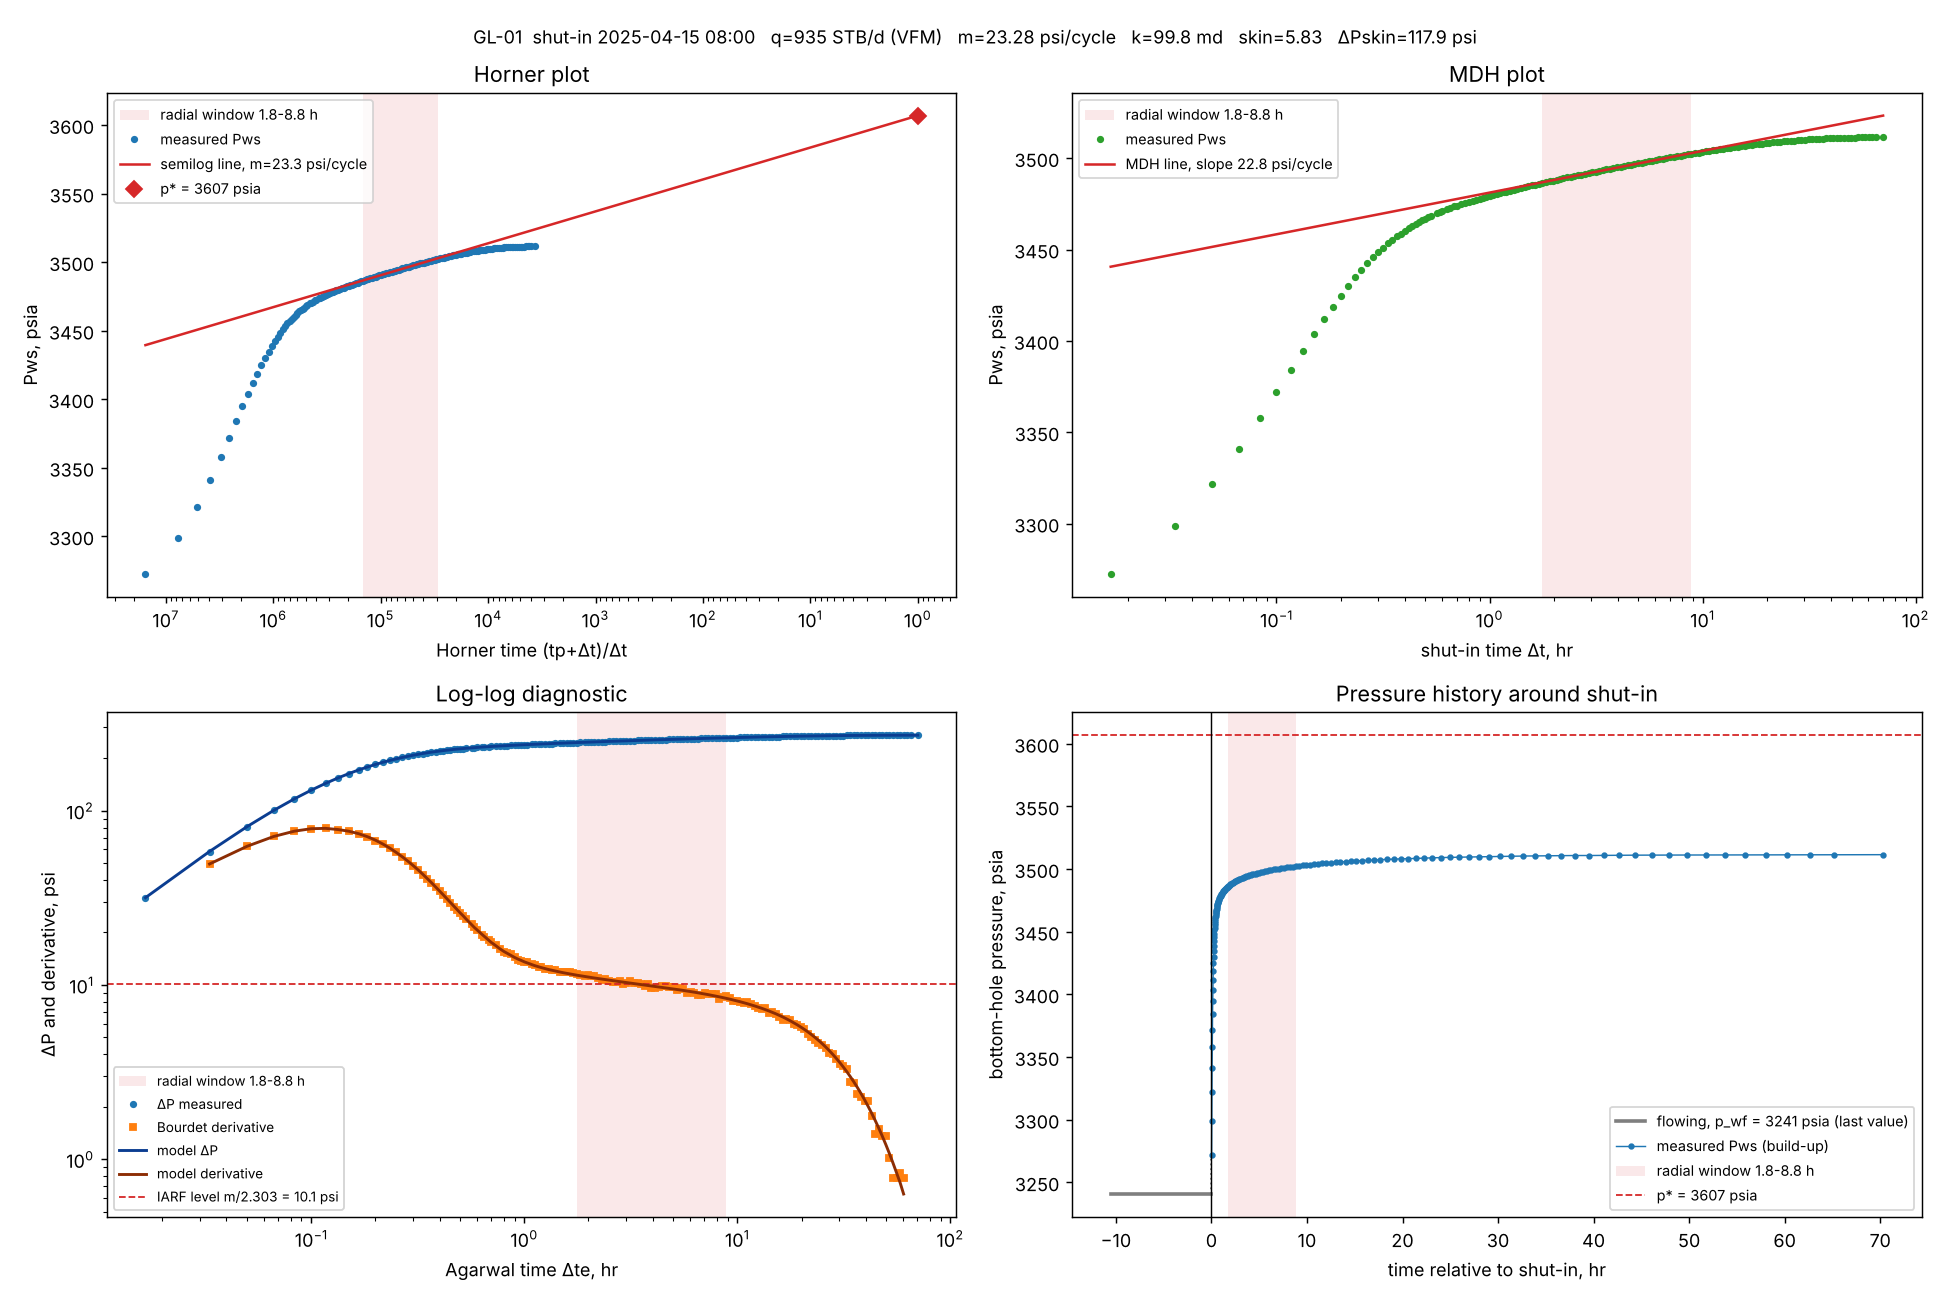

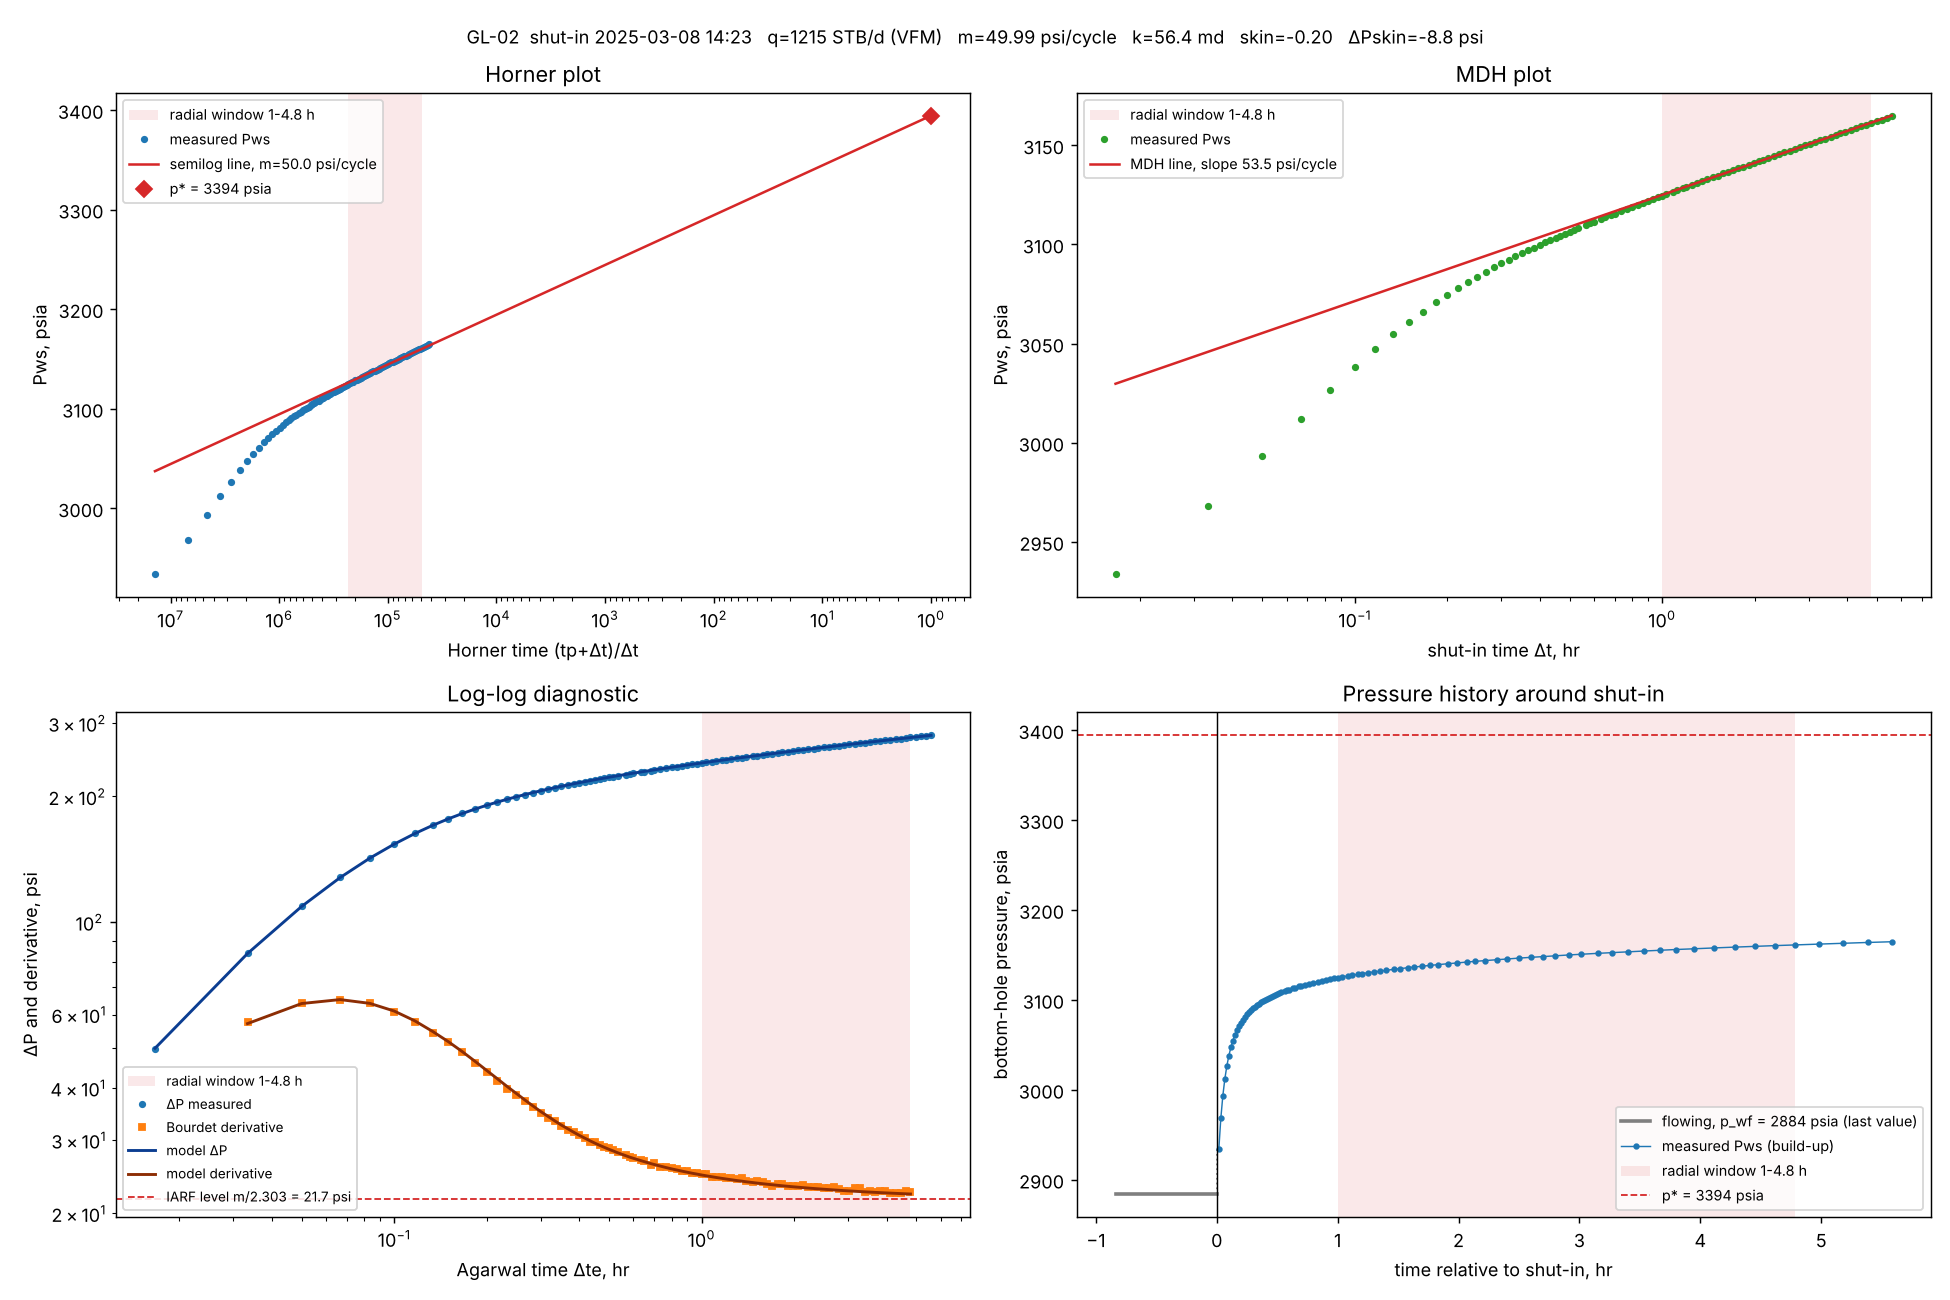

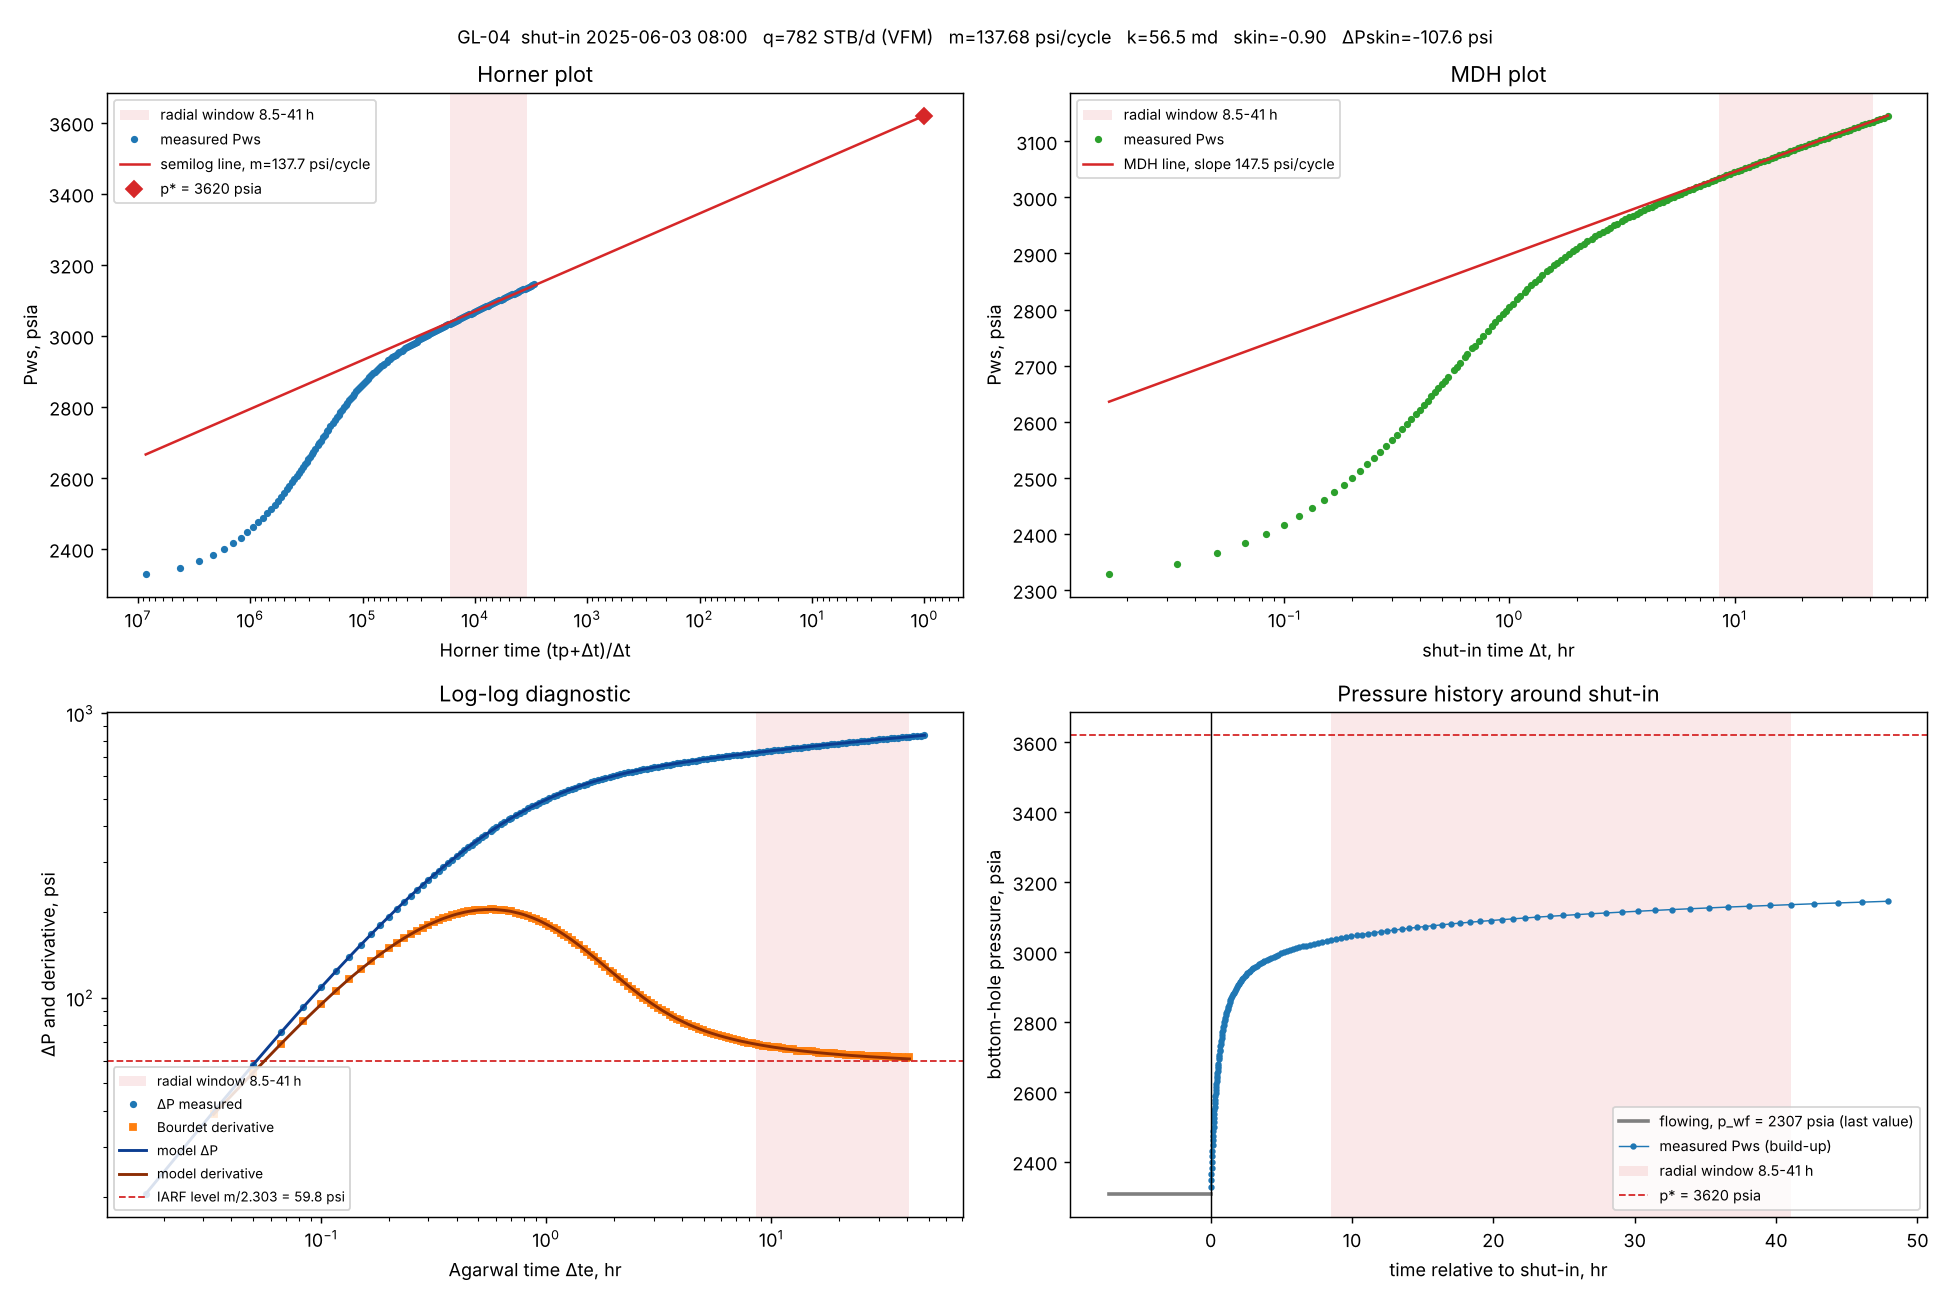

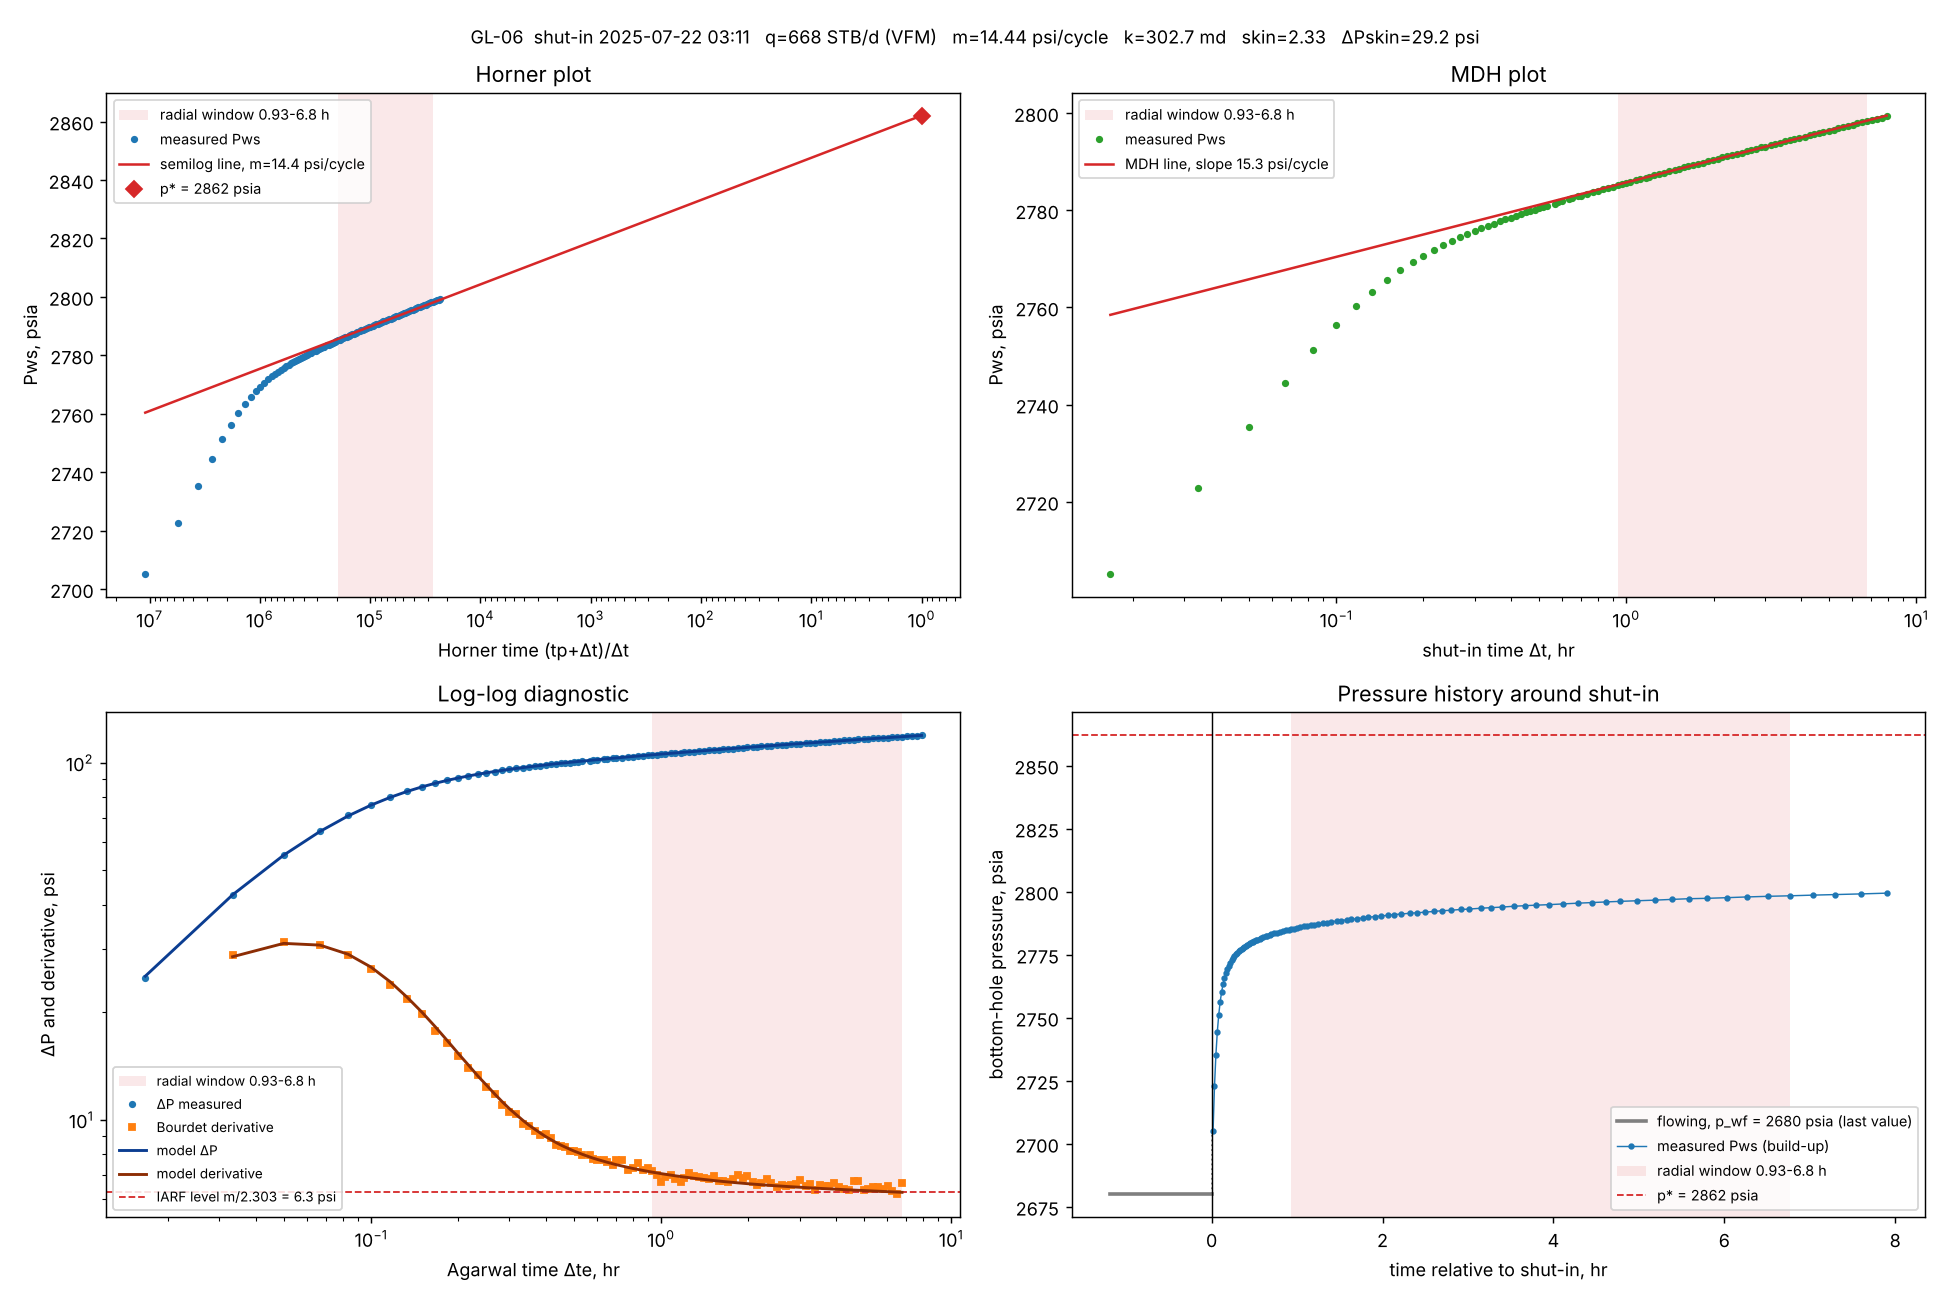

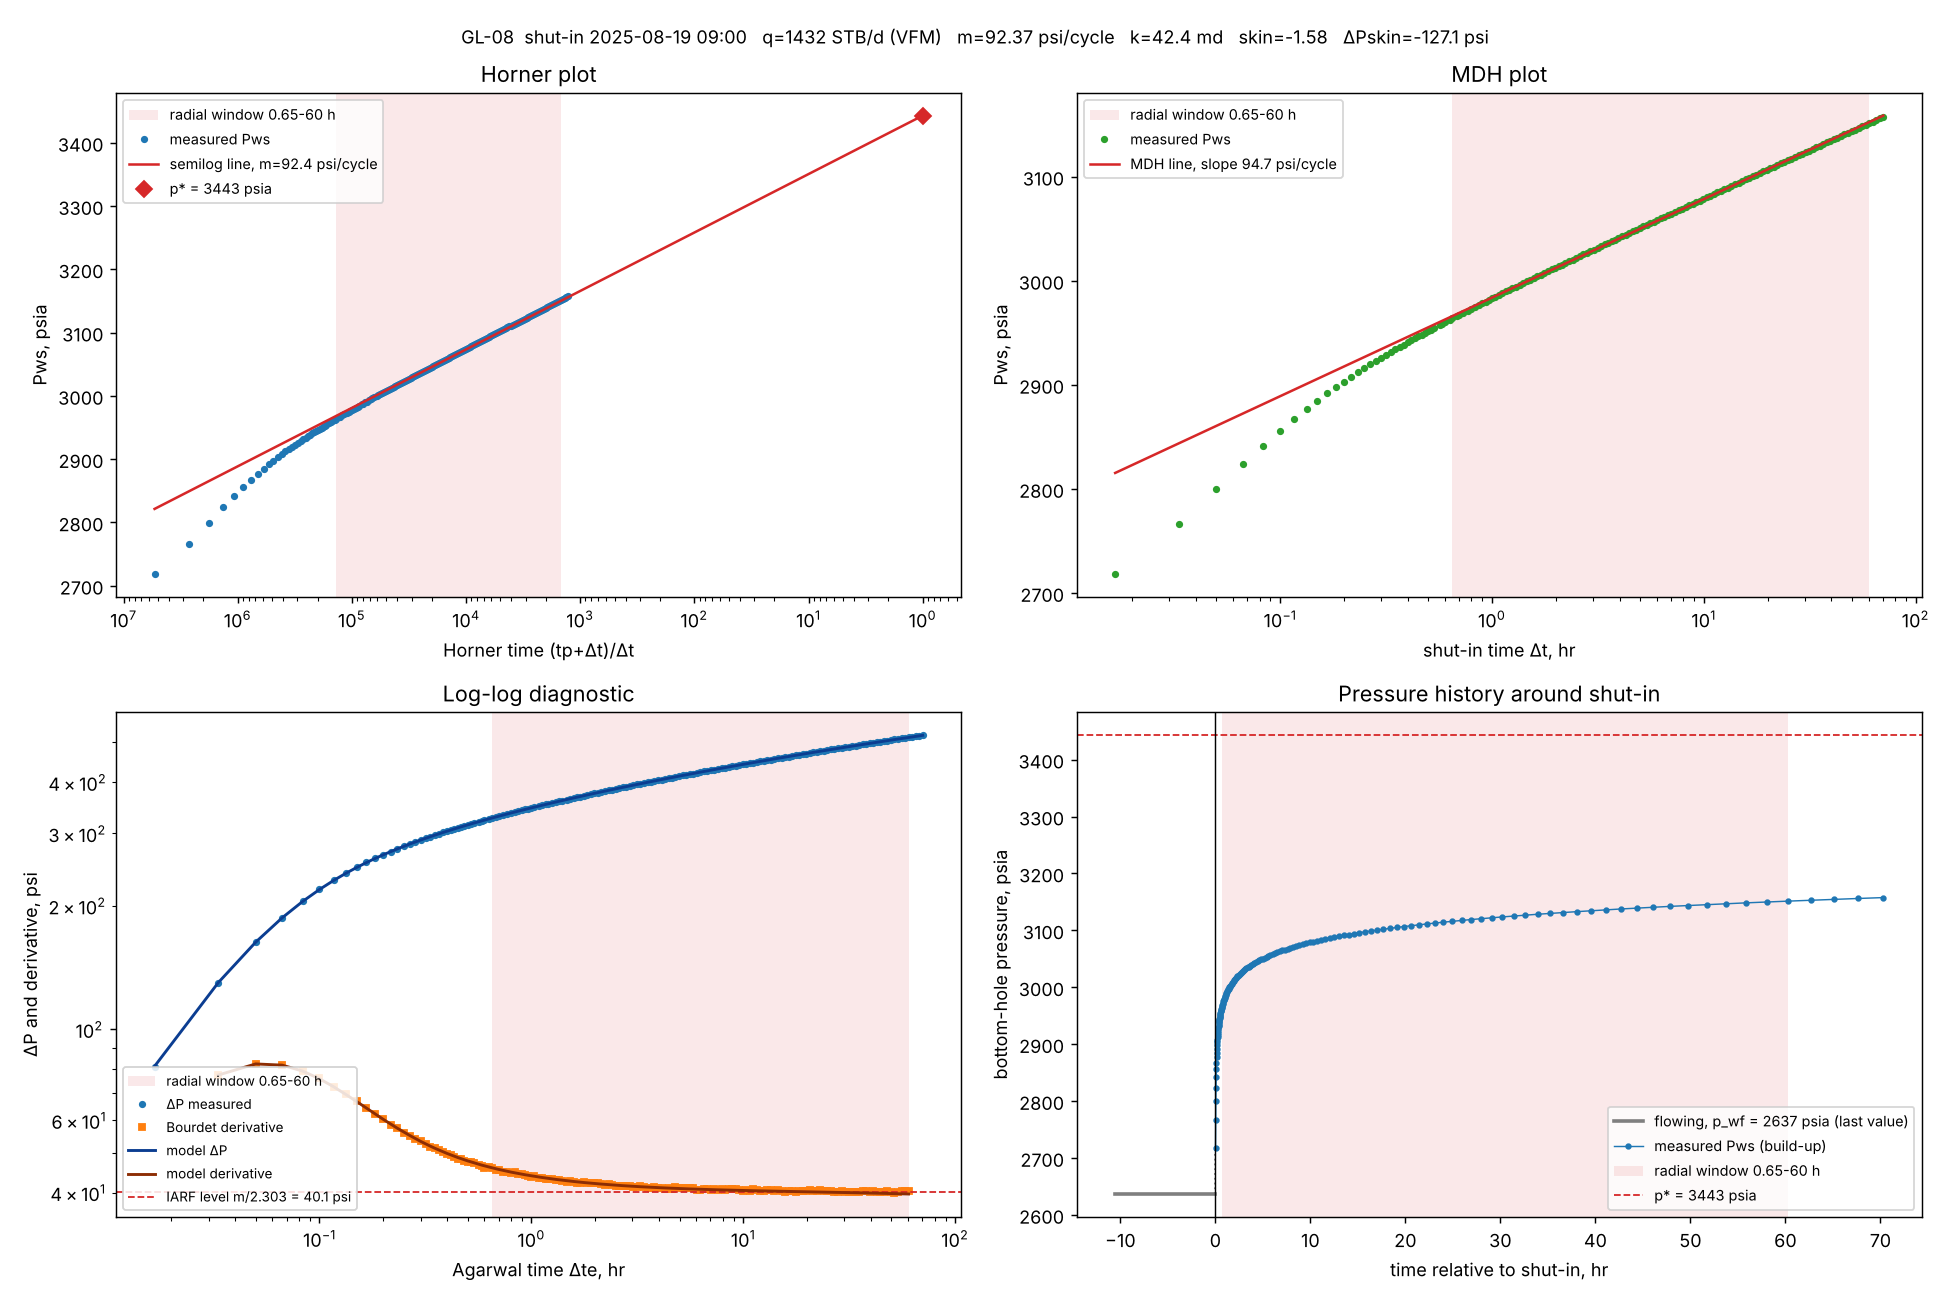

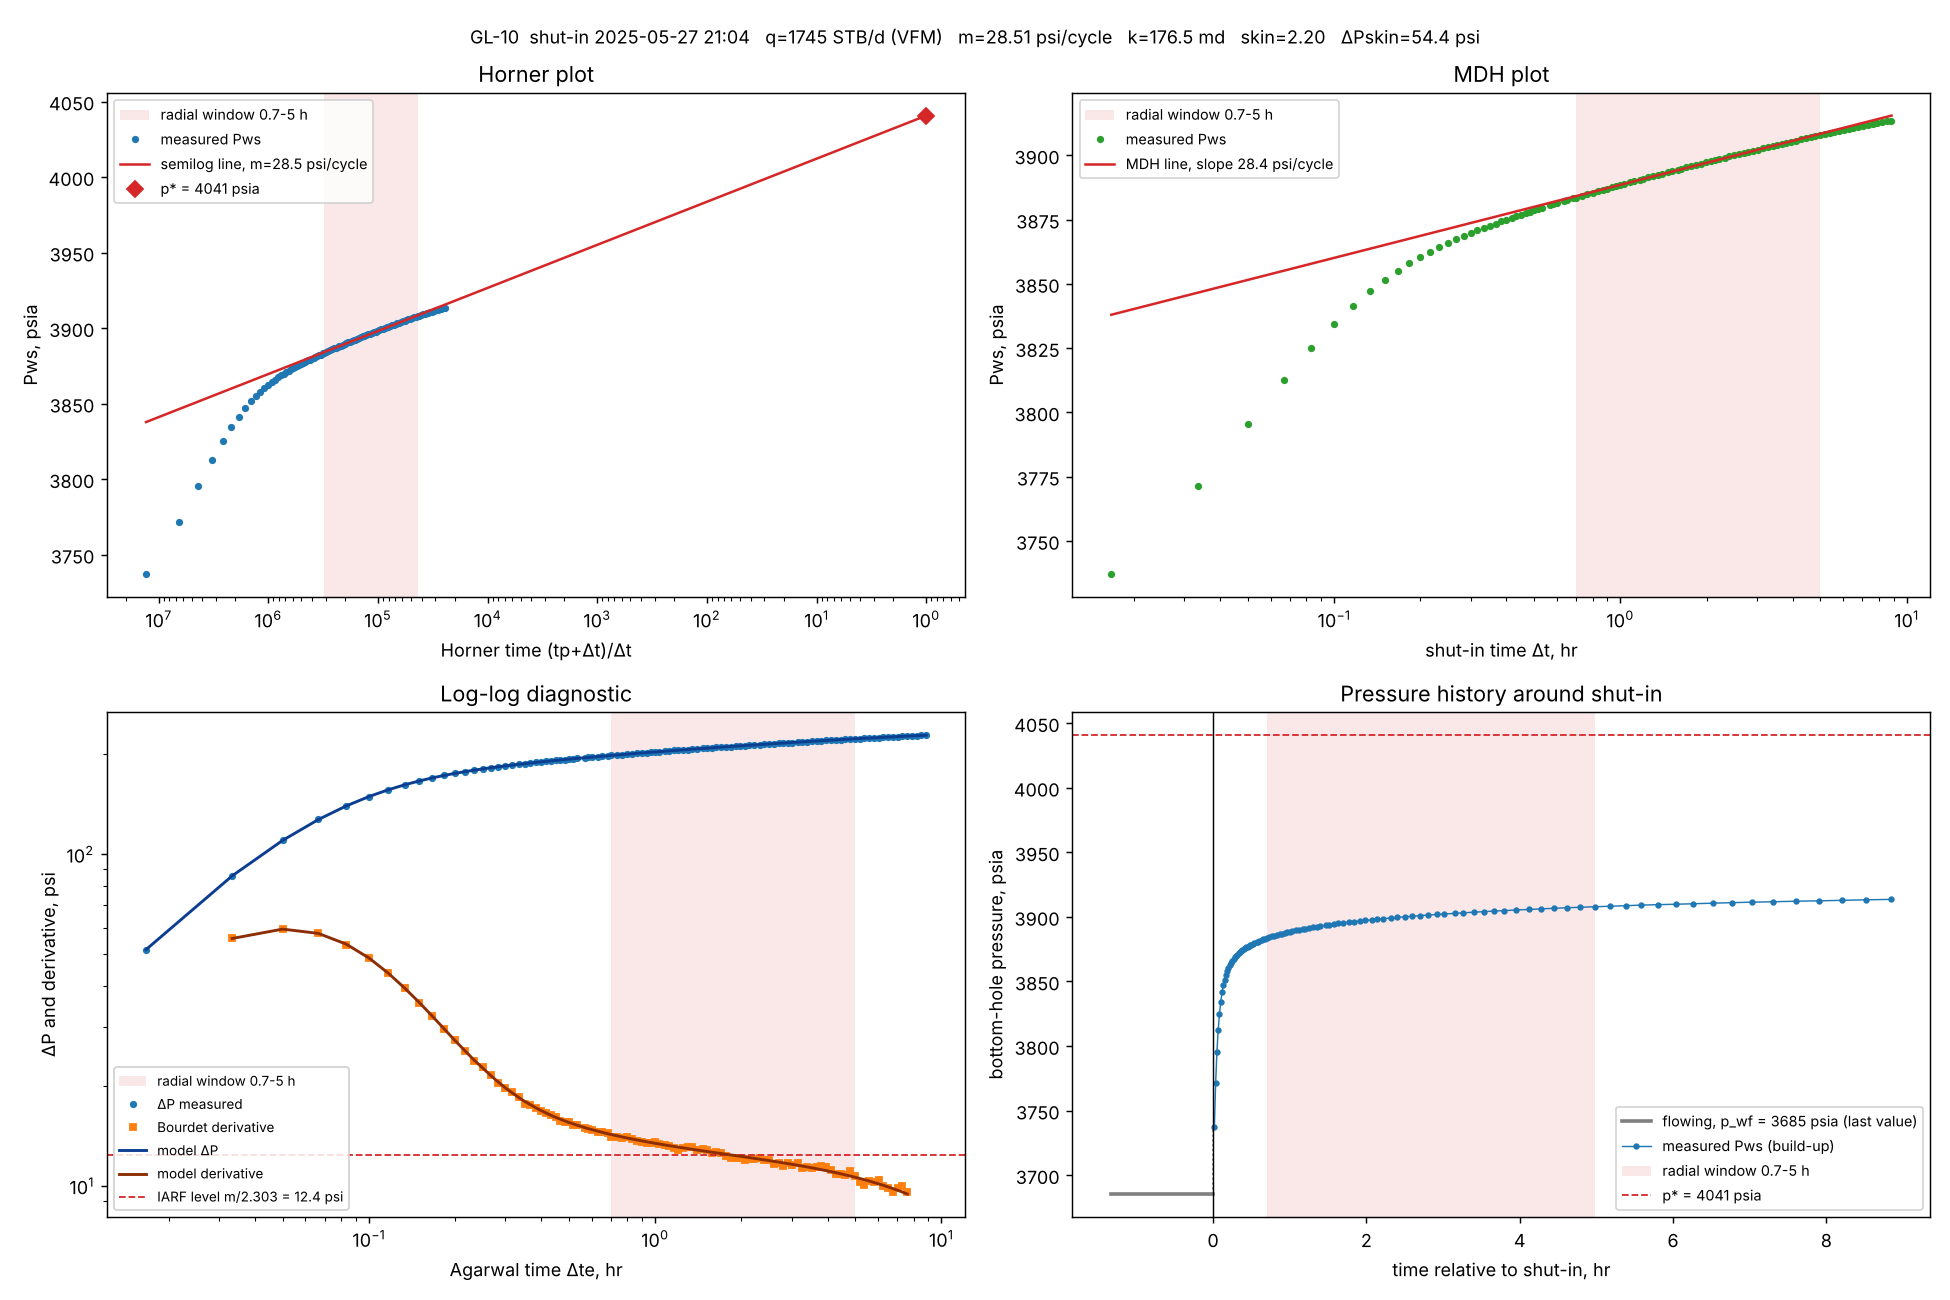

In [22]:
for f in figs: display(Image(f))

### 3.4 Save the Phase 2 result files

In [23]:
with pd.ExcelWriter(f"{OUT}/results/PTA_results.xlsx") as xw:
    official.to_excel(xw, sheet_name="PTA_results", index=False)
    T.to_excel(xw, sheet_name="PTA_details", index=False)
    method_comparison(results).to_excel(xw, sheet_name="Horner_vs_closed_boundary", index=False)
official.to_csv(f"{OUT}/results/PTA_results.csv", index=False)
for root, _, fs in os.walk(OUT):
    for f in sorted(fs): print(os.path.relpath(os.path.join(root, f), ROOT))

submission/model/vfm_model.pkl
submission/run_all/CaspianX_Engineering_Report.html
submission/run_all/PTA_results.xlsx
submission/run_all/VFM_daily_rates.xlsx
submission/run_all/vfm_model.pkl
submission/run_all/plots/PTA_GL-01_20250415_0800.png
submission/run_all/plots/PTA_GL-02_20250308_1423.png
submission/run_all/plots/PTA_GL-04_20250603_0800.png
submission/run_all/plots/PTA_GL-06_20250722_0311.png
submission/run_all/plots/PTA_GL-08_20250819_0900.png
submission/run_all/plots/PTA_GL-10_20250527_2104.png
submission/run_all/plots/vfm_overview.png
submission/run_all/submissions/format_check.txt
submission/run_all/submissions/pta_submission.csv
submission/run_all/submissions/pta_submission.xlsx
submission/run_all/submissions/pta_submission_horner.csv
submission/run_all/submissions/pta_submission_regression.csv
submission/run_all/submissions/vfm_submission.csv
submission/run_all/submissions/vfm_submission.xlsx
submission/run_all/submissions/vfm_submission_ALT_timestamp_datetime.csv
submiss

## 3.5 Template-format check of this notebook's own tables (model A / regression cross-check; the submitted blend + Horner files are produced in 3.6)
Columns and order are read from `templates/vfm_submission_template.csv` and `templates/pta_submission_template.csv`; the same function is used by `run_all.py`.

In [24]:
from pathlib import Path
import run_all
pv, pp = run_all.portal_files(Path(OUT) / "results")
run_all.EXPECTED_WELLS[:] = sorted(daily["well_name"].astype(str).str.strip().unique())   # wells in the input sensor data
chk = run_all.format_checks(pv, pp)   # template/header/sign checks on the tables built in this notebook
print("\n".join(f"{'PASS' if ok else 'FAIL'}  {n}  {d}" for n, ok, d in chk))
display(pv.head()); display(pp)

PASS  VFM columns + order == template  ['timestamp', 'well_name', 'oil_rate_stbd', 'water_rate_stbd', 'gas_rate_mscfd']
PASS  VFM no NaN / empty  
PASS  VFM no negative rates  0 negative
PASS  VFM no Inf (all numeric columns finite)  
PASS  VFM unique (timestamp, well)  
PASS  VFM well names exact (= input sensor wells, stripped)  []
PASS  VFM timestamp parses, one format  2025-01-01
PASS  VFM full calendar x all wells  10 wells x 273 days (2025-01-01..2025-09-30), missing 0 e.g. []
PASS  PTA columns + order == template  ['well_name', 'shut_in_time', 'permeability_md', 'skin', 'delta_p_skin_psi', 'horner_slope']
PASS  PTA no NaN / empty  
PASS  PTA no Inf (all numeric columns finite)  
PASS  PTA one row per well per shut-in  
PASS  PTA well names exact (subset of input wells)  
PASS  PTA shut_in_time format YYYY-MM-DD HH:MM:SS  
PASS  PTA k > 0 and plausible (0.1-10000 md)  
PASS  PTA Horner slope > 0  
PASS  PTA skin plausible (-6..50)  
PASS  PTA sign(skin) == sign(dP_skin)  
PASS  P

,timestamp,well_name,oil_rate_stbd,water_rate_stbd,gas_rate_mscfd
0,2025-01-01,GL-01,1030.52,740.93,285.51
1,2025-01-02,GL-01,1032.24,742.17,285.99
2,2025-01-03,GL-01,1084.75,779.92,300.54
3,2025-01-04,GL-01,1054.23,757.61,292.08
4,2025-01-05,GL-01,1033.17,740.29,286.25


,well_name,shut_in_time,permeability_md,skin,delta_p_skin_psi,horner_slope
0,GL-01,2025-04-15 08:00:00,99.8295,5.8331,117.9467,23.2848
1,GL-02,2025-03-08 14:23:00,56.4466,-0.2035,-8.8318,49.9875
2,GL-04,2025-06-03 08:00:00,56.5259,-0.9003,-107.6397,137.6825
3,GL-06,2025-07-22 03:11:00,302.6952,2.3256,29.1611,14.4397
4,GL-08,2025-08-19 09:00:00,42.3680,-1.5848,-127.1209,92.3677
5,GL-10,2025-05-27 21:04:00,176.4865,2.1975,54.4070,28.5112


## 3.6 Submitted portal files: blend VFM + Horner PTA (`run_all.py`)
`run_all.py` is the one-command pipeline that wrote the files uploaded to the portal. PTA = Horner straight line in the automatic radial window (flattest Bourdet derivative after the storage hump, chosen by code); k = 162.6qBμ/(mh), s = 1.151[(p₁ₕᵣ − p_wf)/m − log₁₀(k/(φμc_t r_w²)) + 3.23], ΔP_skin = 0.87·m·s. The cell re-runs it and checks the output is byte-identical to `results/`.

In [25]:
import filecmp, time
t0 = time.time()
r = subprocess.run([sys.executable, "run_all.py", "--input", D_IN, "--output", f"{OUT}/run_all"], cwd=ROOT, capture_output=True, text=True)
print("run_all exit code", r.returncode, f"({time.time() - t0:.0f} s)")
S = f"{OUT}/run_all/submissions"
for f, ref in [("vfm_submission.csv", "results/phase1_vfm/vfm_submission.csv"), ("pta_submission.csv", "results/phase2_pta/pta_submission.csv")]:
    print(f, "identical to", ref, ":", filecmp.cmp(f"{S}/{f}", f"{ROOT}/{ref}", shallow=False))
print(open(f"{S}/format_check.txt").read()[:1500])
vfm_sub, pta_sub = pd.read_csv(f"{S}/vfm_submission.csv"), pd.read_csv(f"{S}/pta_submission.csv")
print(len(vfm_sub), "VFM rows; NaN:", int(vfm_sub.isna().sum().sum()))
display(pta_sub)

run_all exit code 0 (24 s)
vfm_submission.csv identical to results/phase1_vfm/vfm_submission.csv : True
pta_submission.csv identical to results/phase2_pta/pta_submission.csv : True
VFM rows 2730 | wells 10 | dates 2025-01-01..2025-09-30 | PTA rows 6
PASS  VFM columns + order == template  ['timestamp', 'well_name', 'oil_rate_stbd', 'water_rate_stbd', 'gas_rate_mscfd']
PASS  VFM no NaN / empty  
PASS  VFM no negative rates  0 negative
PASS  VFM no Inf (all numeric columns finite)  
PASS  VFM unique (timestamp, well)  
PASS  VFM well names exact (= input sensor wells, stripped)  []
PASS  VFM timestamp parses, one format  2025-01-01
PASS  VFM full calendar x all wells  10 wells x 273 days (2025-01-01..2025-09-30), missing 0 e.g. []
PASS  PTA columns + order == template  ['well_name', 'shut_in_time', 'permeability_md', 'skin', 'delta_p_skin_psi', 'horner_slope']
PASS  PTA no NaN / empty  
PASS  PTA no Inf (all numeric columns finite)  
PASS  PTA one row per well per shut-in  
PASS  PTA well

,well_name,shut_in_time,permeability_md,skin,delta_p_skin_psi,horner_slope
0,GL-01,2025-04-15 08:00:00,101.3332,5.9329,118.4040,22.9393
1,GL-02,2025-03-08 14:23:00,52.6983,-0.6009,-27.9913,53.5429
2,GL-04,2025-06-03 08:00:00,52.9339,-1.3202,-168.8704,147.0261
3,GL-06,2025-07-22 03:11:00,285.2641,1.8091,24.1156,15.3220
4,GL-08,2025-08-19 09:00:00,41.5465,-1.6930,-138.7399,94.1944
5,GL-10,2025-05-27 21:04:00,180.2234,2.3006,55.8825,27.9200


Portal score of these files (reported by the competition portal, not computed in this notebook): **28.16 / 50** (VFM 19.90 / 30, PTA 8.26 / 20). The provided data contain pressure records for 6 build-ups; the other events listed in the reference file have no pressure data, and no values are invented for them.

### 3.7 Dual-panel PTA diagnostics (log-log + Bourdet derivative | Horner), one per build-up
Left: ΔP and derivative with wellbore-storage, radial-flow (IARF) and late-time zones. Right: Horner semilog with the radial-window fit, m and p₁ₕᵣ. The box shows the VFM oil rate used (and its source day), t_p, k, s, ΔP_skin and the PVT inputs.

PTA_GL-01_20250415_0800.png


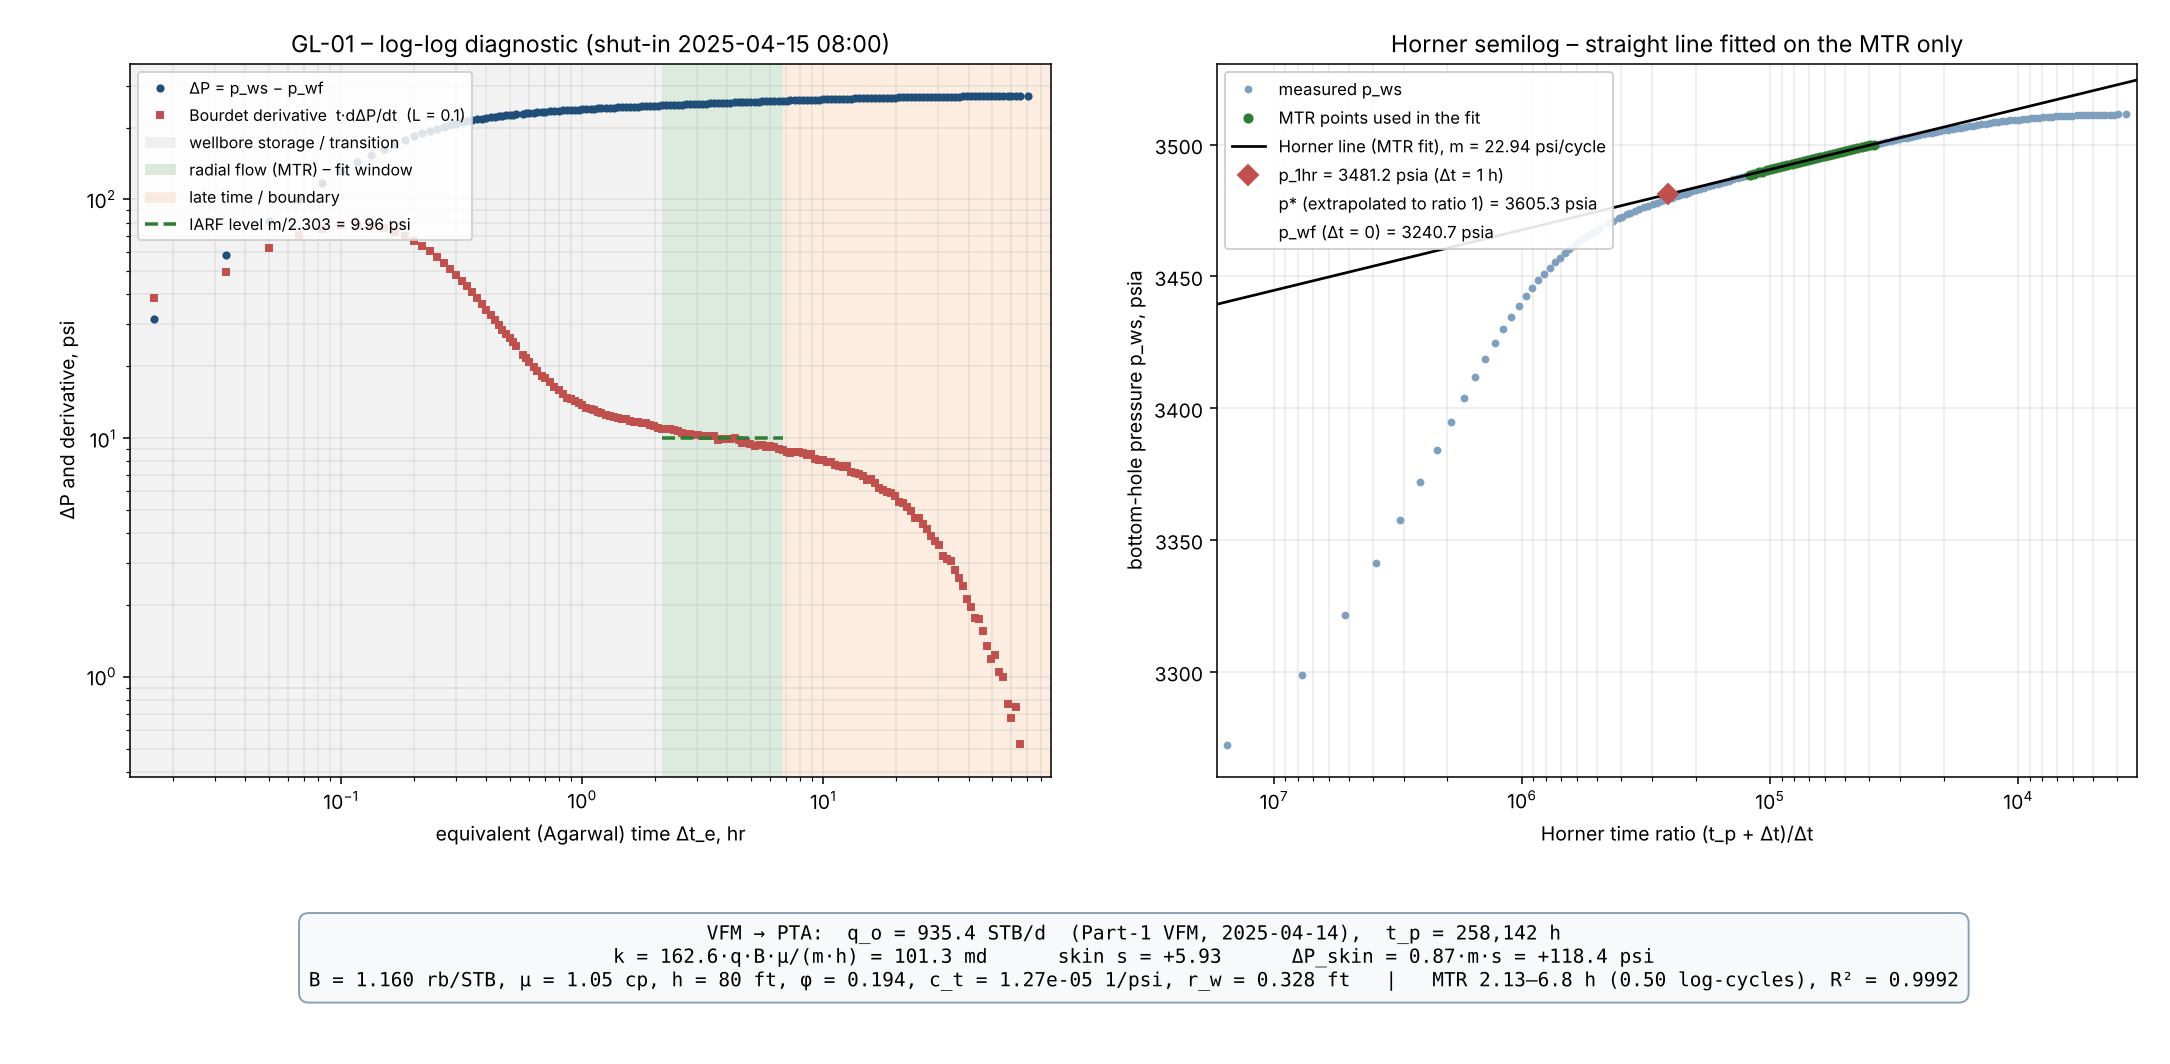

PTA_GL-02_20250308_1423.png


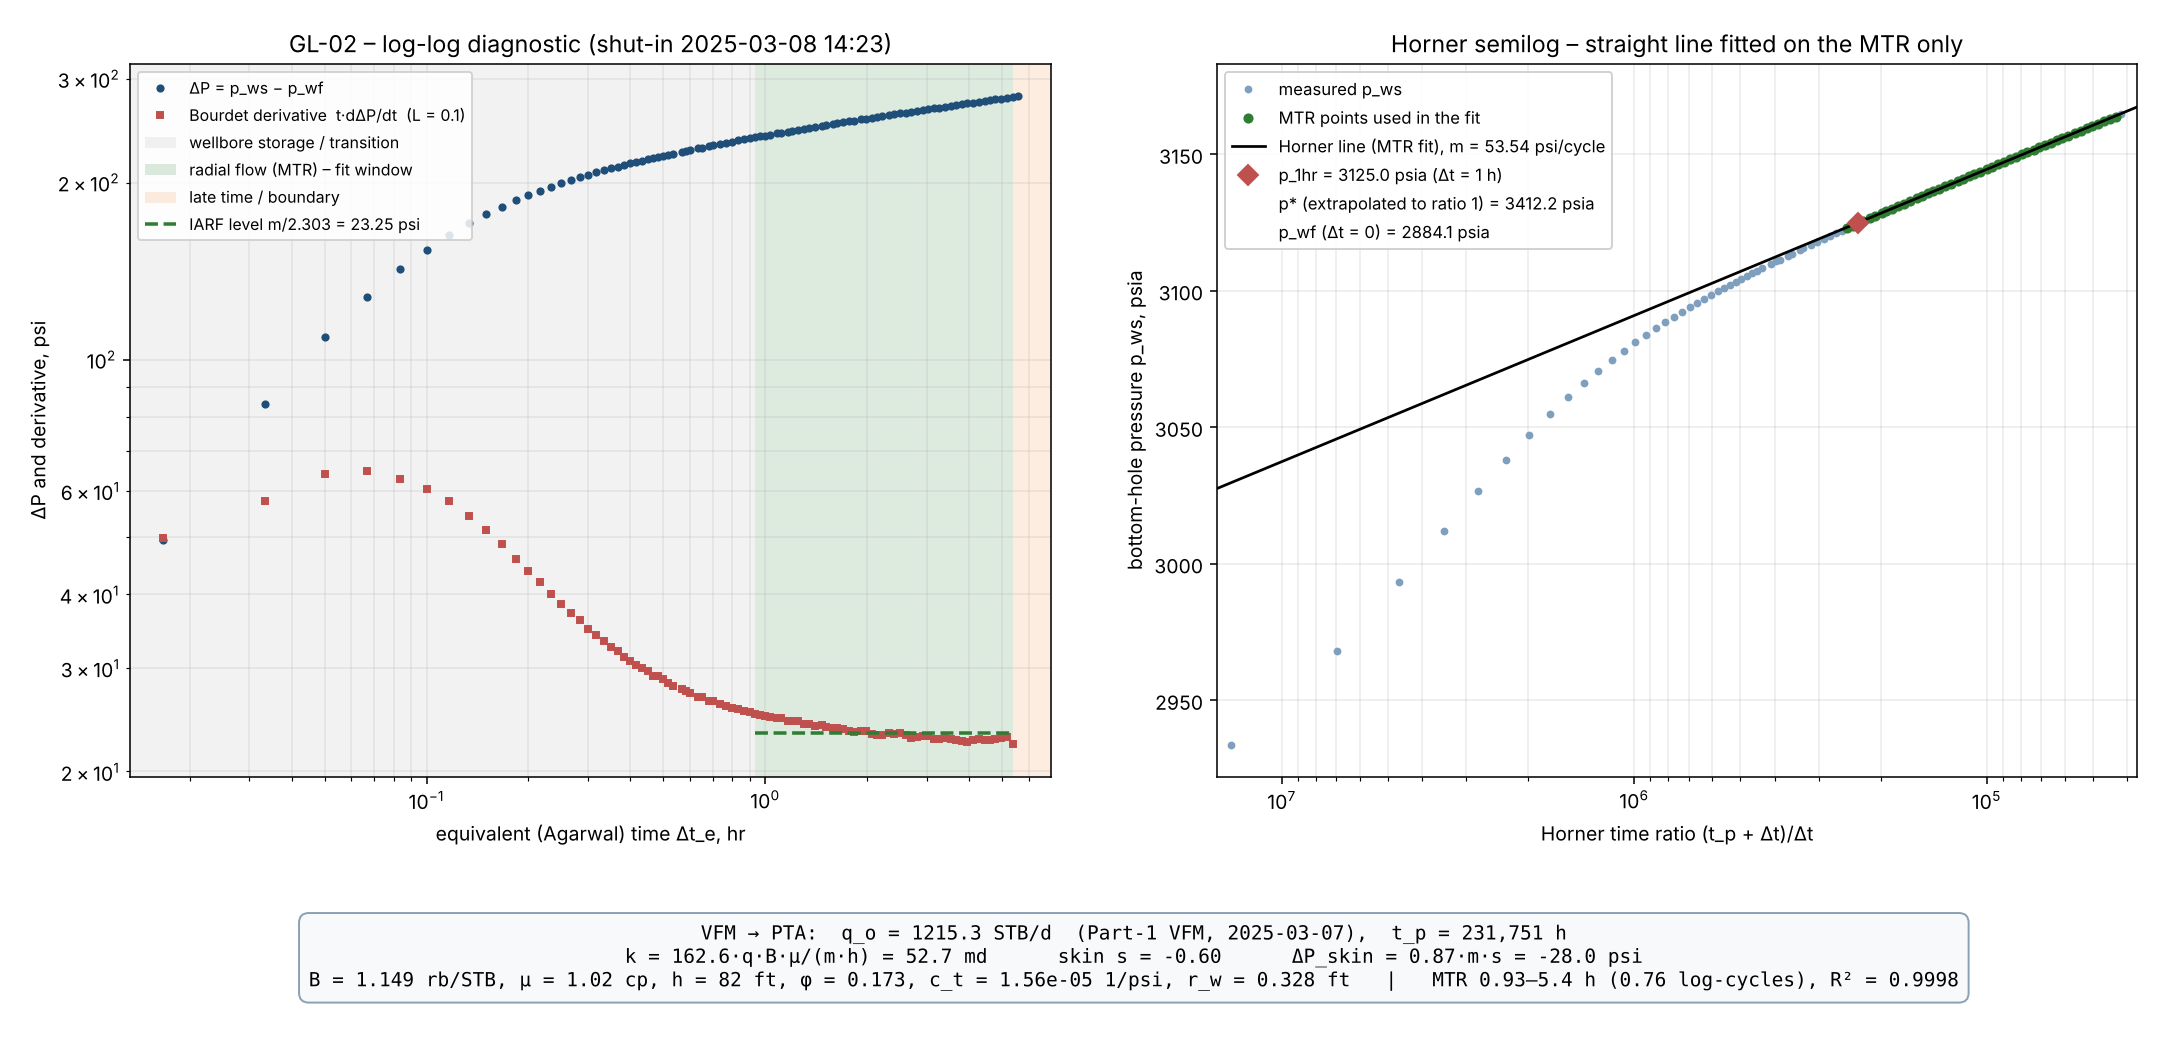

PTA_GL-04_20250603_0800.png


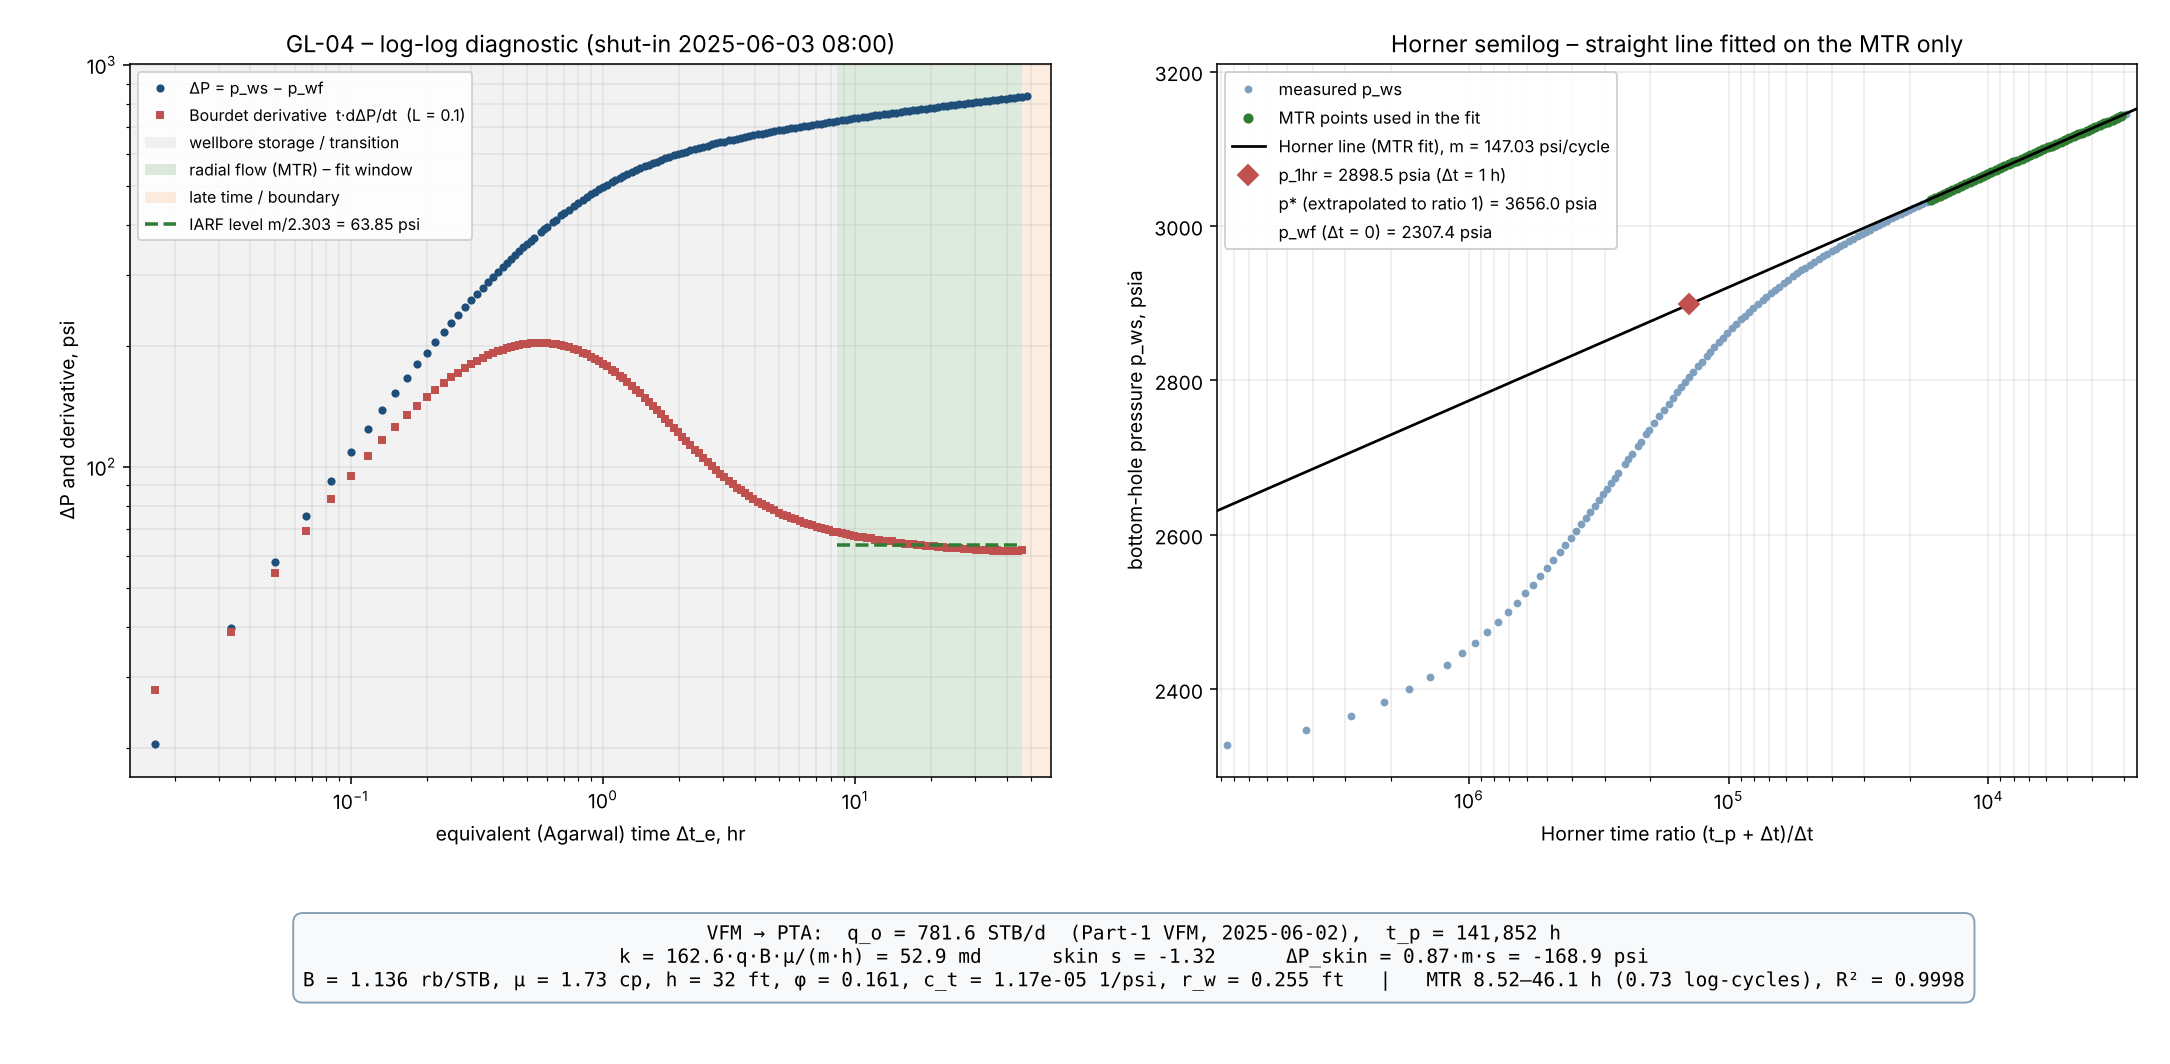

PTA_GL-06_20250722_0311.png


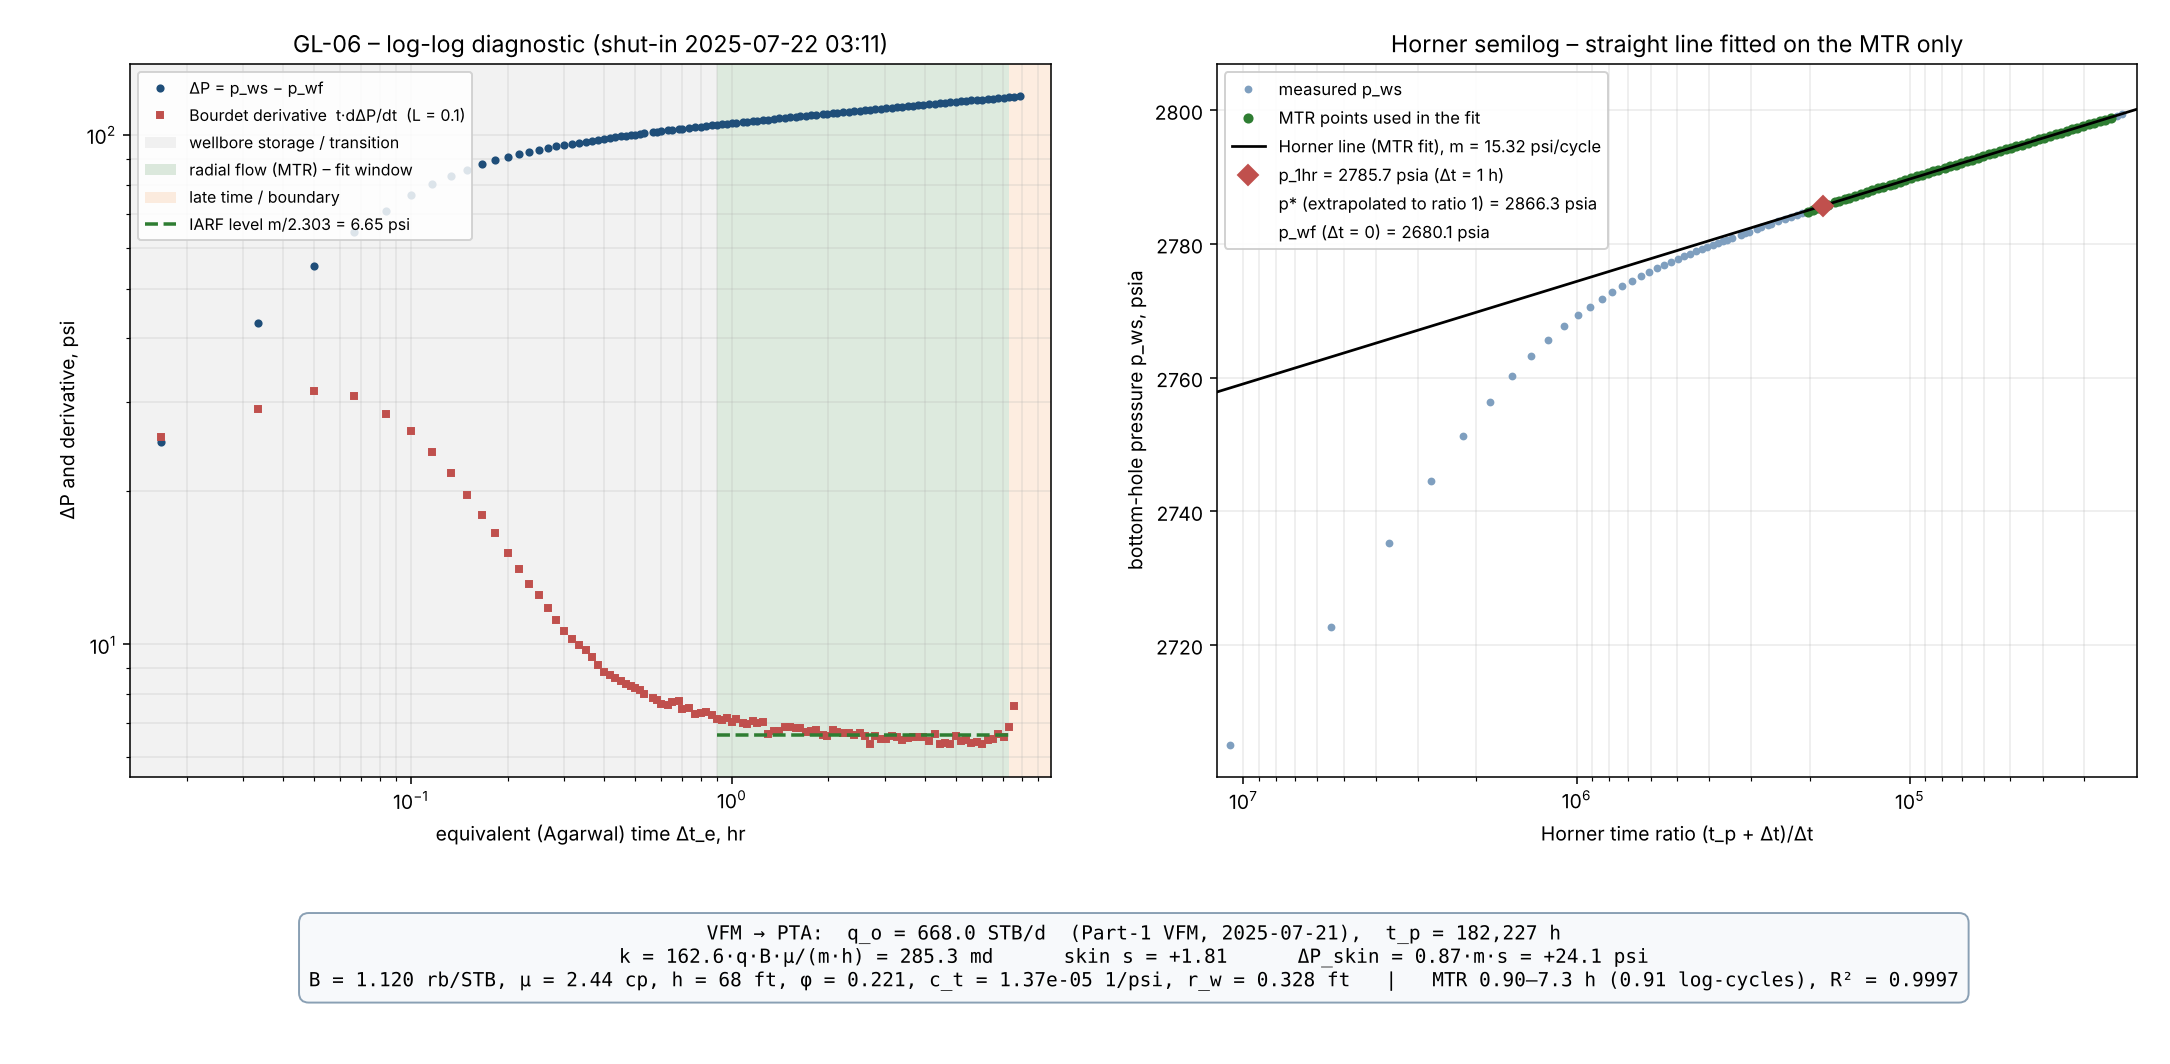

PTA_GL-08_20250819_0900.png


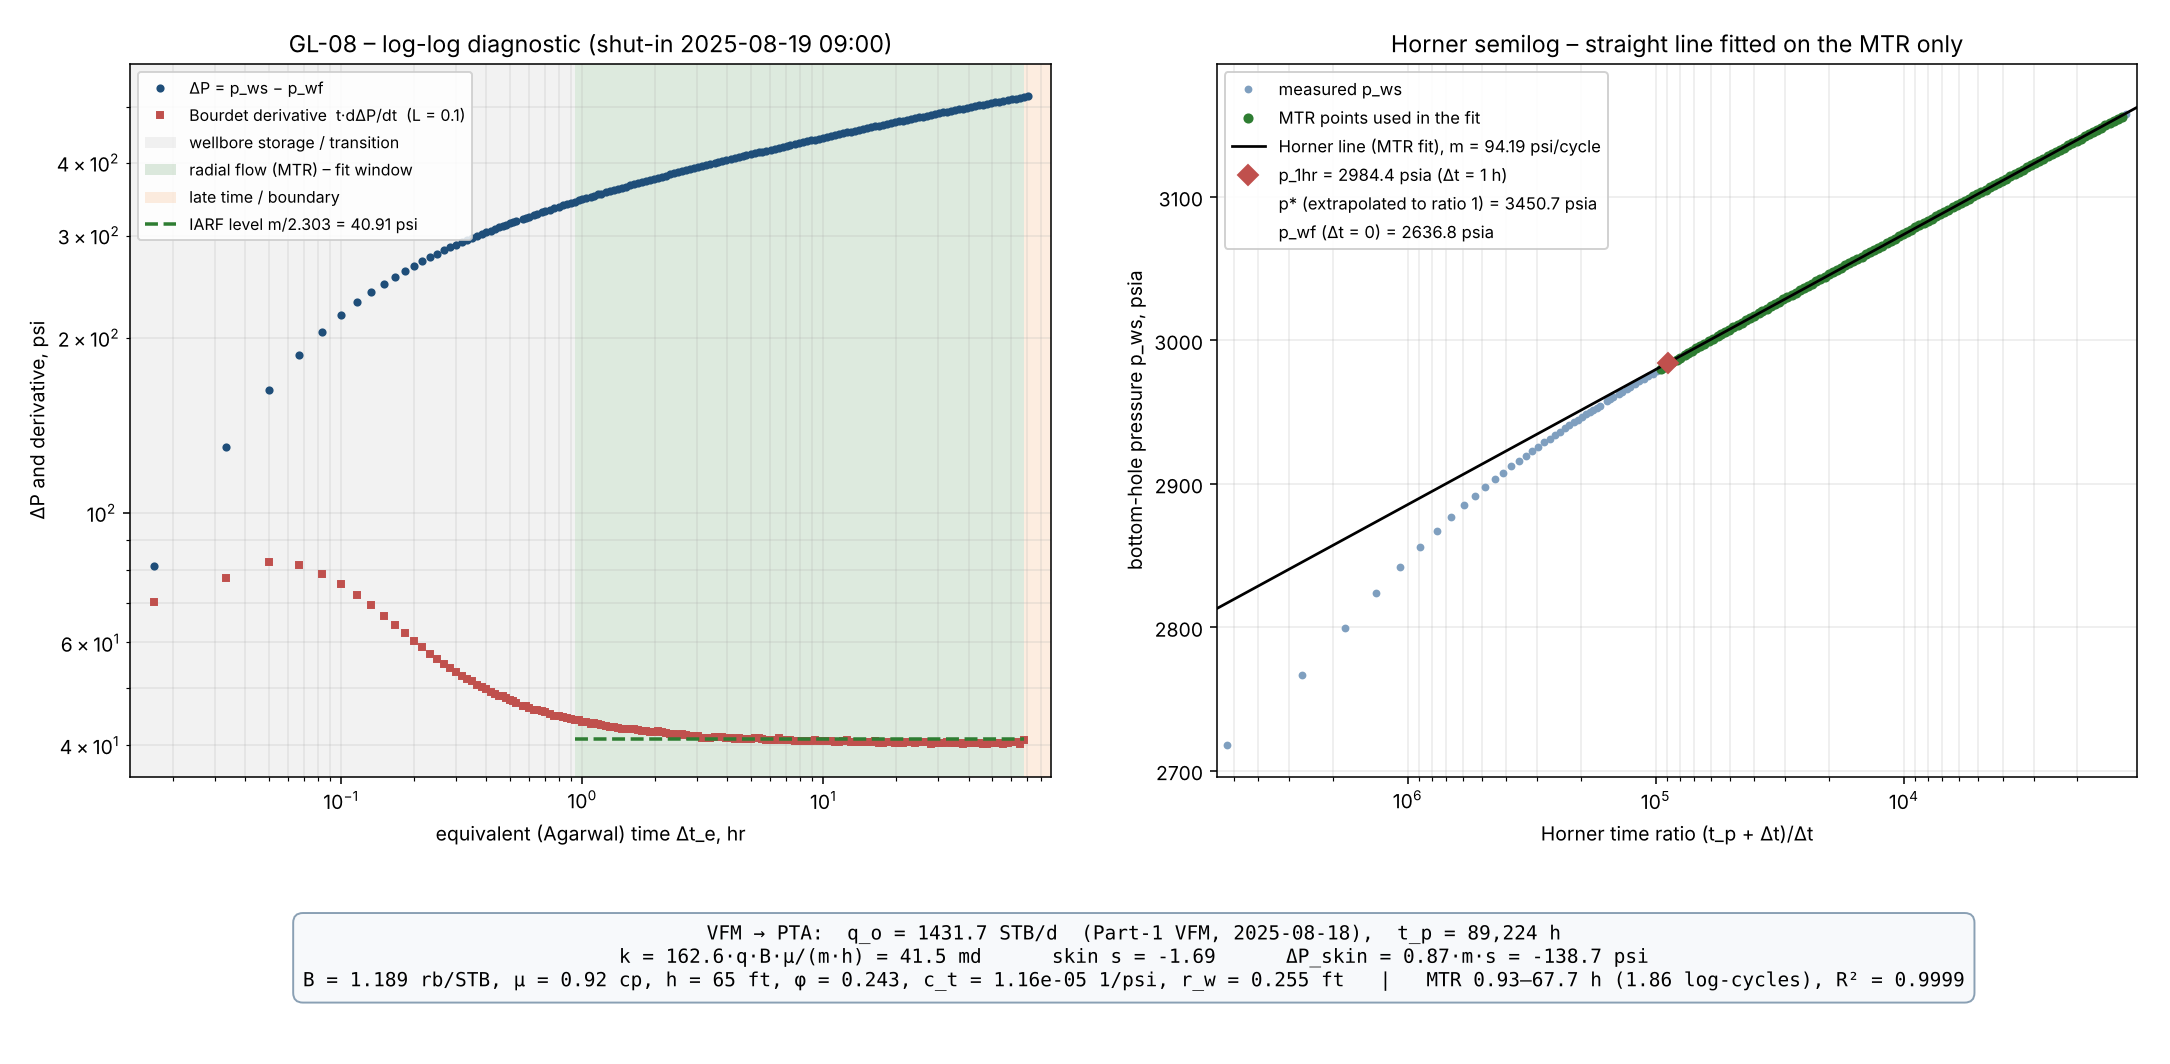

PTA_GL-10_20250527_2104.png


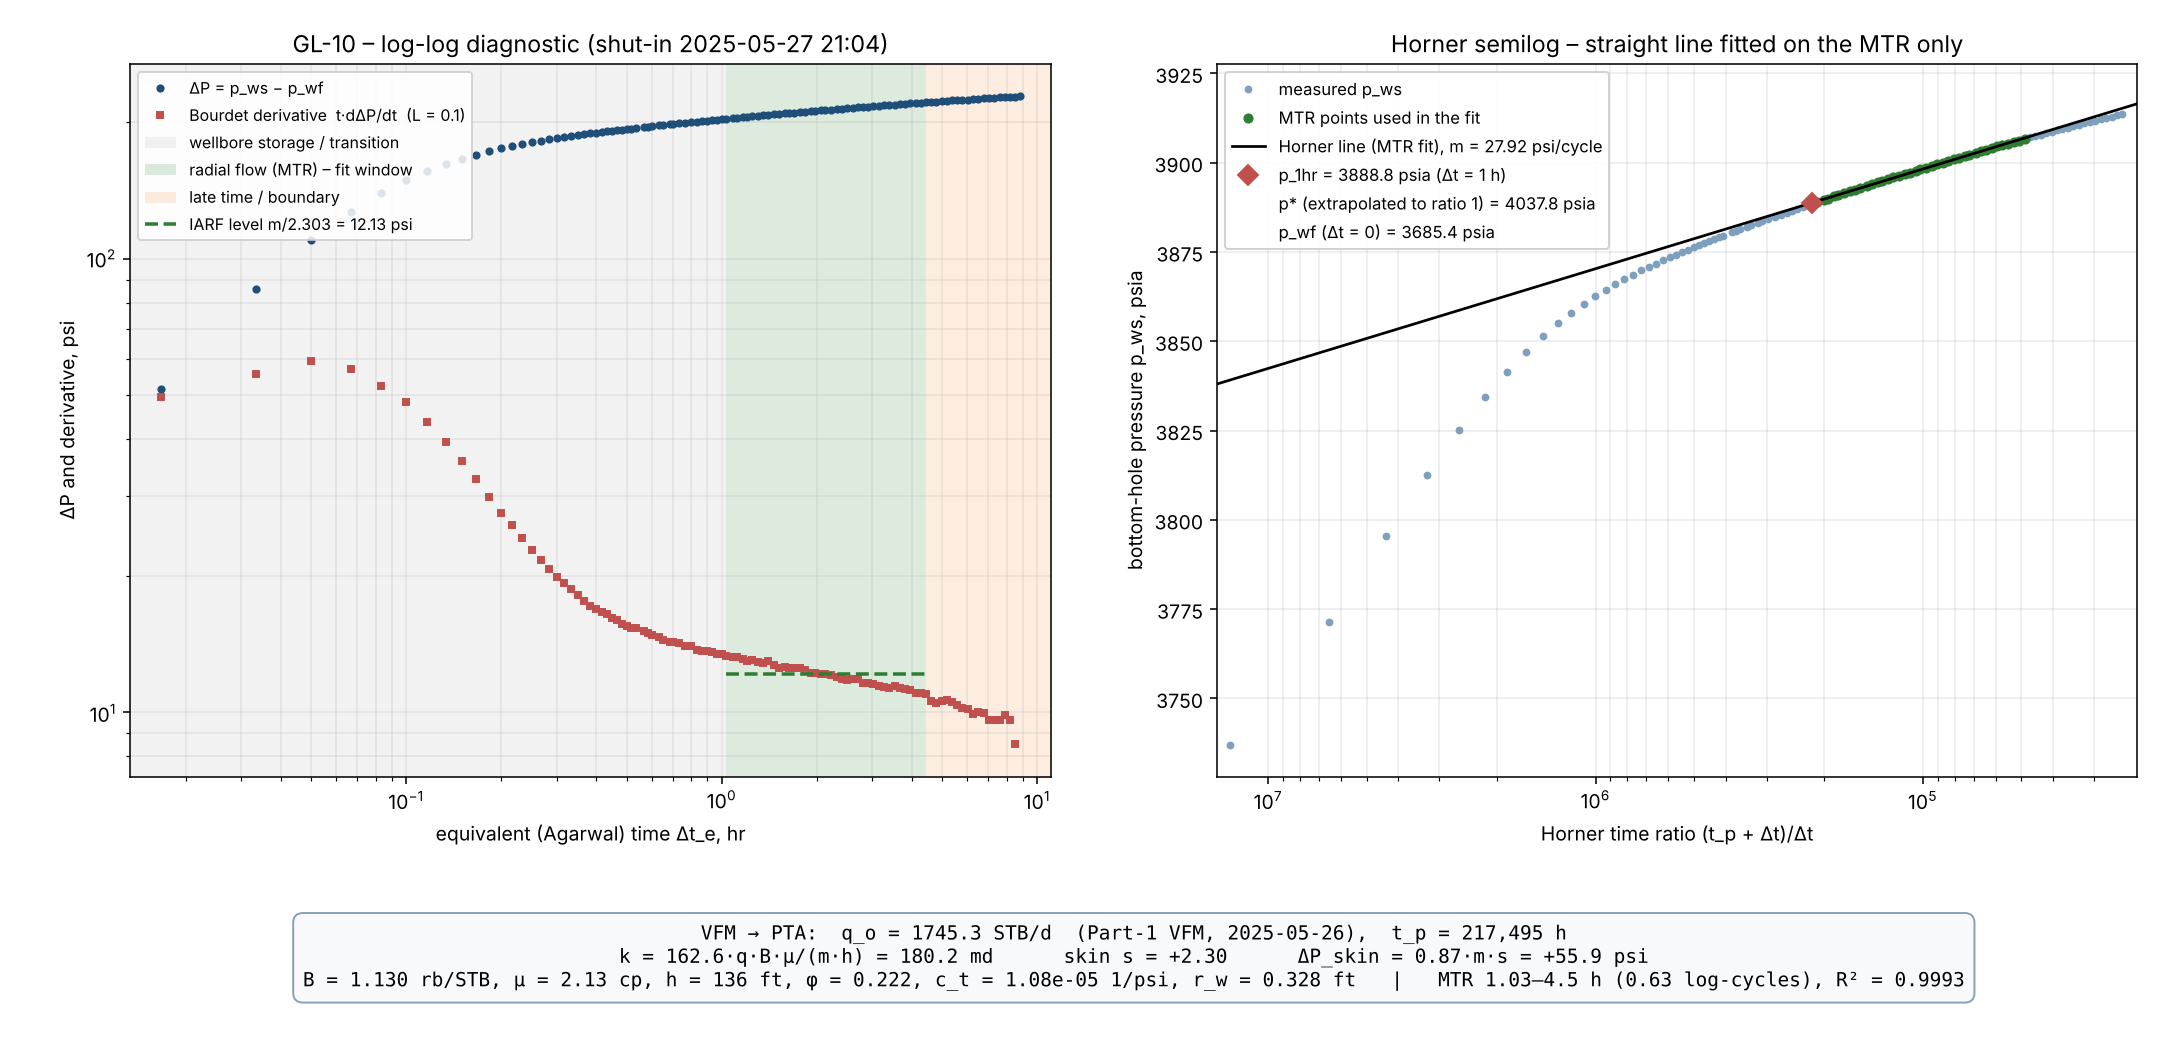

In [26]:
for f in sorted(glob.glob(f"{OUT}/run_all/pta_plots/PTA_*.png")):
    print(os.path.basename(f)); display(Image(f, width=1100))

## 4. Application
`streamlit run app.py` opens the SOCAR-style application (left rail: drop data → Run VFM → Run PTA → Export → well). It loads `models/vfm_model.pkl` and `models/vfm_model_B.pkl` without retraining, shows field measurements, VFM rates with P10–P90 and the error-rate card, the dual-panel PTA plots with k, S, m, Δp_skin and an automatic interpretation, a choke What-If capped at realistic openings, and exports the template-format CSV/XLSX files and an HTML report. Without the data folder it opens in results mode. `app_console.py` is the full engineering console.